# Do AI Explanations Reveal Model Mistakes? A Controlled Evaluation of Grad-CAM
**DS5622 – Explainable AI · Track 1 · Gnanamayi (142301009), Megha Harsha (142301036)**

This notebook runs the **whole project end to end**: training → predictions → explanations → metrics → RQ1/RQ2 → sanity check → deletion (RQ3) → RQ4 → sensitivity analysis → failure cases → summary.

### How to run
1. **Runtime → Change runtime type → T4 GPU.**
2. **First run with `DEBUG = True`** (cell 0.2) → *Runtime → Run all*. This trains for a few batches and uses only 500 test images, so the whole pipeline finishes in about 10–15 minutes. It exists only to catch errors. **Ignore the numbers from this run.**
3. Set **`DEBUG = False`** → *Runtime → Run all* again. This is the real experiment (roughly 1.5–2.5 hours on a T4; training is the longest part).
4. Everything is saved to **Google Drive** (`MyDrive/xai-gradcam-mistakes/results/`). If Colab disconnects, just *Run all* again: finished work (model, explanations, deletion chunks) is **loaded from disk**, not recomputed.

### What you get
* `results/figures/` – all figures **F1–F14** (PNG, ready for the report)
* `results/tables/` – all tables **T1–T6** (CSV + Markdown)
* `results/summary.json` – every key number in one file
* `results/predictions.csv` – one row per test image with all metrics

Each step starts with a short **Why / What** note and ends with **what to check**.

---
# STEP 0 — Setup

In [ ]:
# 0.1  Install the two XAI libraries (used only to cross-check our own implementations)
!pip install -q grad-cam captum

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
# 0.2  Imports, configuration, paths
import os, json, time, copy, random, shutil, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as T
import torchvision.transforms.functional as TF
from scipy import stats
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix
from skimage.metrics import structural_similarity
warnings.filterwarnings("ignore")

DEBUG = False       # <-- FIRST run with True (quick test of the whole pipeline). Then set False for the real run.
USE_DRIVE = True   # save results to Google Drive (recommended: survives disconnects)

CFG = dict(
    seed=42,
    # --- training ---
    epochs=2 if DEBUG else 30,
    train_limit_batches=30 if DEBUG else 0,      # 0 = use all batches
    batch_size=128, lr=0.1, momentum=0.9, weight_decay=5e-4,
    # --- analysis set ---
    n_test=500 if DEBUG else 10000,              # number of CIFAR-10 test images analysed
    # --- groups ---
    cm_quantile=0.75,          # confident mistakes = errors with confidence >= 75th percentile of error confidences (top 25%)
    cm_quantile_strict=0.90,   # sensitivity: top 10% of errors
    cm_abs_threshold=0.90,     # sensitivity: errors with confidence >= 0.9
    # --- deletion experiment ---
    ks=[round(k, 2) for k in np.arange(0, 0.501, 0.05)],   # fraction of pixels deleted: 0, 5, ..., 50 %
    mask_modes=["black", "mean", "blur"],
    blur_kernel=7, blur_sigma=2.0,
    n_random_draws=5, patch_size=4, n_patches=150,
    deletion_batch=200, deletion_chunk=1000,
    # --- sanity check ---
    sanity_n=100 if DEBUG else 1000,
    # --- statistics ---
    n_boot=200 if DEBUG else 1000,
    conf_bin_width=0.05,       # bin width for confidence matching (RQ4)
    n_fail_examples=6,
)

if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = Path("/content/drive/MyDrive/xai-gradcam-mistakes")
else:
    ROOT = Path("/content/xai-gradcam-mistakes")
RES = ROOT / ("results_debug" if DEBUG else "results")
FIG, TAB, EXPL_DIR, DEL_DIR = RES / "figures", RES / "tables", RES / "explanations", RES / "deletion"
for d in [FIG, TAB, EXPL_DIR, DEL_DIR]:
    d.mkdir(parents=True, exist_ok=True)
DATA = Path("/content/data")
with open(RES / "config.json", "w") as f:
    json.dump(CFG, f, indent=2)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
AMP = DEVICE == "cuda"
print("Results folder:", RES)
print("Device:", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU  <-- WARNING: change runtime to GPU!")
print("torch", torch.__version__, "| torchvision", torchvision.__version__, "| DEBUG =", DEBUG)

Mounted at /content/drive
Results folder: /content/drive/MyDrive/xai-gradcam-mistakes/results
Device: Tesla T4
torch 2.14.1+cu130 | torchvision 0.29.1+cu130 | DEBUG = False


In [ ]:
# 0.3  General helpers (seeding, saving figures/tables, collecting key results)
def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
    os.environ["PYTHONHASHSEED"] = str(s)

set_seed(CFG["seed"])
torch.backends.cudnn.benchmark = True
plt.rcParams.update({"figure.dpi": 100, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})

RESULTS = {}   # every key number goes here -> summary.json

def _to_py(o):
    if hasattr(o, "item"): return o.item()
    if isinstance(o, (np.ndarray,)): return o.tolist()
    return str(o)

def save_results():
    with open(RES / "summary.json", "w") as f:
        json.dump(RESULTS, f, indent=2, default=_to_py)

def savefig(fig, name):
    st = getattr(fig, "_suptitle", None)
    if st is not None:                      # keep the title above the panels (no overlap)
        try: fig.tight_layout()
        except Exception: pass
        st.set_y(1.0); st.set_va("bottom")
    fig.savefig(FIG / f"{name}.png", dpi=200, bbox_inches="tight")
    plt.show(); plt.close(fig)
    print("saved figure ->", name)

def save_table(df_, name, show=True):
    df_.to_csv(TAB / f"{name}.csv", index=False)
    try:
        (TAB / f"{name}.md").write_text(df_.to_markdown(index=False))
    except Exception:
        pass
    if show: display(df_)
    print("saved table ->", name)
    return df_

In [ ]:
# 0.4  Statistics helpers (pure NumPy / SciPy)
RNG = np.random.default_rng(CFG["seed"])

def _clean(a):
    a = np.asarray(a, float); return a[~np.isnan(a)]

def rb_ind(a, b):
    """Mann-Whitney U test for two INDEPENDENT groups.
    Effect size r = P(a > b) - P(a < b)  (rank-biserial). r > 0 means a tends to be larger."""
    a, b = _clean(a), _clean(b)
    if len(a) < 2 or len(b) < 2: return np.nan, np.nan
    res = stats.mannwhitneyu(a, b, alternative="two-sided")
    return 2 * res.statistic / (len(a) * len(b)) - 1, res.pvalue

def rb_paired(a, b):
    """Wilcoxon signed-rank test for PAIRED values (same image, two methods).
    Effect size: matched-pairs rank-biserial r on d = a - b. r > 0 means a tends to be larger."""
    d = np.asarray(a, float) - np.asarray(b, float)
    d = d[~np.isnan(d)]; d = d[d != 0]
    if len(d) < 2: return np.nan, np.nan
    rk = stats.rankdata(np.abs(d))
    wp, wm = rk[d > 0].sum(), rk[d < 0].sum()
    return (wp - wm) / (wp + wm), stats.wilcoxon(d).pvalue

def boot_ci(fn, arrays, B=None, rng=RNG):
    """Percentile bootstrap 95% CI for a statistic of INDEPENDENT groups (each resampled separately)."""
    B = B or CFG["n_boot"]
    arrays = [_clean(a) for a in arrays]
    if any(len(a) < 2 for a in arrays): return (np.nan, np.nan)
    vals = [fn(*[a[rng.integers(0, len(a), len(a))] for a in arrays]) for _ in range(B)]
    return tuple(np.nanpercentile(vals, [2.5, 97.5]))

def mean_ci(a):
    a = _clean(a); m = a.mean(); se = a.std(ddof=1) / np.sqrt(len(a))
    return m, m - 1.96 * se, m + 1.96 * se

def auroc_ci(y, s, B=None, rng=RNG):
    """AUROC with a stratified bootstrap 95% CI. y = 1 for the positive class (e.g. mistakes)."""
    B = B or CFG["n_boot"]
    y = np.asarray(y).astype(int); s = np.asarray(s, float)
    ok = ~np.isnan(s); y, s = y[ok], s[ok]
    if y.sum() < 2 or (1 - y).sum() < 2: return (np.nan, np.nan, np.nan)
    auc = roc_auc_score(y, s)
    pos, neg = np.where(y == 1)[0], np.where(y == 0)[0]
    bs = []
    for _ in range(B):
        i = np.concatenate([rng.choice(pos, len(pos)), rng.choice(neg, len(neg))])
        bs.append(roc_auc_score(y[i], s[i]))
    lo, hi = np.percentile(bs, [2.5, 97.5])
    return (auc, lo, hi)

def holm(p):
    """Holm-Bonferroni correction (NaNs ignored)."""
    p = np.asarray(p, float); adj = np.full_like(p, np.nan)
    ok = np.where(~np.isnan(p))[0]
    order = ok[np.argsort(p[ok])]; m = len(order); running = 0.0
    for rank, i in enumerate(order):
        running = max(running, (m - rank) * p[i]); adj[i] = min(running, 1.0)
    return adj

def rowwise_spearman(A, B):
    """Spearman correlation between matching rows of A and B (e.g. two heatmaps of the same image)."""
    ra = stats.rankdata(A, axis=1); rb = stats.rankdata(B, axis=1)
    ra = ra - ra.mean(1, keepdims=True); rb = rb - rb.mean(1, keepdims=True)
    den = np.sqrt((ra ** 2).sum(1) * (rb ** 2).sum(1))
    with np.errstate(invalid="ignore", divide="ignore"):
        return (ra * rb).sum(1) / den

def matched_controls(conf, case_mask, control_mask, width, rng=RNG):
    """For every case (e.g. a mistake) draw one control (e.g. a correct image) from the same confidence bin."""
    bins = np.floor(np.asarray(conf) / width).astype(int)
    cases = np.where(case_mask)[0]
    pools = {b: np.where(control_mask & (bins == b))[0] for b in np.unique(bins[cases])}
    kept, ctrl = [], []
    for i in cases:
        pool = pools[bins[i]]
        if len(pool):
            kept.append(i); ctrl.append(rng.choice(pool))
    return np.array(kept, int), np.array(ctrl, int)

def verdict(effect, p_adj, expected_sign):
    if effect is None or np.isnan(effect) or np.isnan(p_adj): return "–"
    if p_adj < 0.05 and np.sign(effect) == expected_sign: return "✓ supported"
    if p_adj < 0.05: return "✗ opposite direction"
    return "✗ not significant"

def stars(p):
    if np.isnan(p): return ""
    return "***" if p < 1e-3 else "**" if p < 1e-2 else "*" if p < 0.05 else "ns"

def fmt_ci(v, lo, hi, d=3):
    return f"{v:.{d}f} [{lo:.{d}f}, {hi:.{d}f}]"

print("helpers ready")

helpers ready


In [ ]:
# 0.5  Model and data
MEAN = (0.4914, 0.4822, 0.4465)
STD = (0.2470, 0.2435, 0.2616)
CLASSES = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]

class NormalizedResNet18(nn.Module):
    """ResNet-18 adapted to 32x32 CIFAR images (3x3 stem, no max-pool) with normalisation INSIDE the model.
    Input = raw images in [0, 1]  ->  masking with 'black' really means black.
    Feature-map sizes: layer1 32x32, layer2 16x16, layer3 8x8, layer4 4x4."""
    def __init__(self, num_classes=10):
        super().__init__()
        net = torchvision.models.resnet18(weights=None, num_classes=num_classes)
        net.conv1 = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False)
        net.maxpool = nn.Identity()
        self.net = net
        self.register_buffer("mean", torch.tensor(MEAN).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor(STD).view(1, 3, 1, 1))
    def forward(self, x):
        return self.net((x - self.mean) / self.std)

def get_model():
    return NormalizedResNet18().to(DEVICE)

train_tf = T.Compose([T.RandomCrop(32, padding=4), T.RandomHorizontalFlip(), T.ToTensor()])
train_ds = torchvision.datasets.CIFAR10(DATA, train=True, download=True, transform=train_tf)
test_ds = torchvision.datasets.CIFAR10(DATA, train=False, download=True)

# Whole test set as one tensor in a FIXED order (index i is the same image in every step)
X_ALL = torch.tensor(test_ds.data).permute(0, 3, 1, 2).float().div(255)
Y_ALL = torch.tensor(test_ds.targets)
N = CFG["n_test"]
X_TEST, Y_TEST = X_ALL[:N].contiguous(), Y_ALL[:N].clone()
print("train:", len(train_ds), "| test (analysed):", N)

@torch.no_grad()
def predict_probs(model, X, bs=1000, amp=False):
    model.eval(); out = []
    for i in range(0, len(X), bs):
        with torch.autocast("cuda", dtype=torch.float16, enabled=amp and AMP):
            out.append(F.softmax(model(X[i:i + bs].to(DEVICE)).float(), 1).cpu())
    return torch.cat(out)

100%|██████████| 170M/170M [07:40<00:00, 370kB/s]


train: 50000 | test (analysed): 10000


---
# STEP 1 — Train the classifier
**Why:** we need a well-trained model so that its mistakes are *genuine* model mistakes (cat↔dog, deer on grass…), not random noise from undertraining.
**What:** CIFAR-adapted ResNet-18, SGD + Nesterov, cosine learning-rate schedule, 30 epochs, mixed precision. A checkpoint is saved every epoch (training resumes automatically after a disconnect).
**Check:** final test accuracy ≈ **93–95 %**, and train/test curves level off together.

In [ ]:
# 1.1  Train (or load if already trained)
MODEL_PATH, CKPT_PATH, LOG_PATH = RES / "model.pt", RES / "checkpoint.pt", RES / "training_log.csv"
set_seed(CFG["seed"])
model = get_model()

if MODEL_PATH.exists():
    model.load_state_dict(torch.load(MODEL_PATH, map_location=DEVICE))
    print("Loaded trained model from Drive -> skipping training.")
else:
    g = torch.Generator(); g.manual_seed(CFG["seed"])
    train_loader = torch.utils.data.DataLoader(train_ds, batch_size=CFG["batch_size"], shuffle=True,
                                               num_workers=2, pin_memory=True, drop_last=True, generator=g)
    opt = torch.optim.SGD(model.parameters(), lr=CFG["lr"], momentum=CFG["momentum"],
                          weight_decay=CFG["weight_decay"], nesterov=True)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=CFG["epochs"])
    scaler = torch.amp.GradScaler("cuda", enabled=AMP)
    crit = nn.CrossEntropyLoss()
    log, start_epoch = [], 1
    if CKPT_PATH.exists():
        ck = torch.load(CKPT_PATH, map_location=DEVICE, weights_only=False)
        model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"])
        sched.load_state_dict(ck["sched"]); scaler.load_state_dict(ck["scaler"])
        log, start_epoch = ck["log"], ck["epoch"] + 1
        print(f"Resuming training from epoch {start_epoch}")

    for epoch in range(start_epoch, CFG["epochs"] + 1):
        model.train(); t0 = time.time(); tl = tc = tn = 0
        for i, (x, y) in enumerate(train_loader):
            if CFG["train_limit_batches"] and i >= CFG["train_limit_batches"]: break
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast("cuda", dtype=torch.float16, enabled=AMP):
                out = model(x); loss = crit(out, y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tl += loss.item() * len(y); tc += (out.argmax(1) == y).sum().item(); tn += len(y)
        lr_now = opt.param_groups[0]["lr"]; sched.step()
        probs = predict_probs(model, X_ALL, amp=True)
        te_acc = (probs.argmax(1) == Y_ALL).float().mean().item()
        te_loss = F.nll_loss(torch.log(probs.clamp_min(1e-12)), Y_ALL).item()
        log.append(dict(epoch=epoch, lr=lr_now, train_loss=tl / tn, train_acc=tc / tn,
                        test_loss=te_loss, test_acc=te_acc, time_s=time.time() - t0))
        print(f"epoch {epoch:02d}/{CFG['epochs']} | lr {lr_now:.4f} | train acc {tc/tn:.4f} | "
              f"test acc {te_acc:.4f} | {time.time()-t0:.0f}s")
        torch.save(dict(model=model.state_dict(), opt=opt.state_dict(), sched=sched.state_dict(),
                        scaler=scaler.state_dict(), log=log, epoch=epoch), CKPT_PATH)
    torch.save(model.state_dict(), MODEL_PATH)
    pd.DataFrame(log).to_csv(LOG_PATH, index=False)
    print("Training finished.")
model.eval()
for p_ in model.parameters():
    p_.requires_grad_(True)

epoch 01/30 | lr 0.1000 | train acc 0.1701 | test acc 0.2671 | 27s
epoch 02/30 | lr 0.0997 | train acc 0.3868 | test acc 0.4682 | 20s
epoch 03/30 | lr 0.0989 | train acc 0.5143 | test acc 0.5741 | 22s
epoch 04/30 | lr 0.0976 | train acc 0.6248 | test acc 0.6337 | 21s
epoch 05/30 | lr 0.0957 | train acc 0.7042 | test acc 0.6635 | 22s
epoch 06/30 | lr 0.0933 | train acc 0.7612 | test acc 0.7712 | 21s
epoch 07/30 | lr 0.0905 | train acc 0.7934 | test acc 0.7851 | 23s
epoch 08/30 | lr 0.0872 | train acc 0.8136 | test acc 0.8053 | 22s
epoch 09/30 | lr 0.0835 | train acc 0.8290 | test acc 0.8155 | 23s
epoch 10/30 | lr 0.0794 | train acc 0.8390 | test acc 0.8010 | 22s
epoch 11/30 | lr 0.0750 | train acc 0.8473 | test acc 0.7674 | 23s
epoch 12/30 | lr 0.0703 | train acc 0.8581 | test acc 0.7945 | 22s
epoch 13/30 | lr 0.0655 | train acc 0.8690 | test acc 0.8235 | 22s
epoch 14/30 | lr 0.0604 | train acc 0.8756 | test acc 0.8362 | 22s
epoch 15/30 | lr 0.0552 | train acc 0.8828 | test acc 0.8456 |

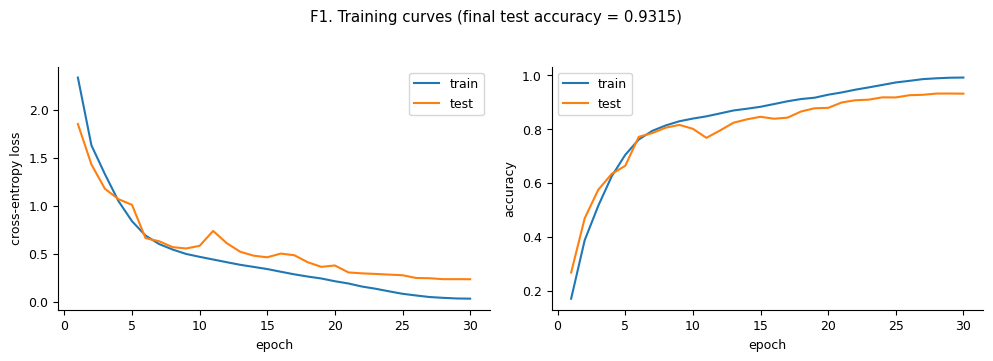

saved figure -> F1_training_curves


In [ ]:
# 1.2  F1 – training curves
if LOG_PATH.exists():
    log = pd.read_csv(LOG_PATH)
    RESULTS["test_acc_full_test_set"] = float(log.test_acc.iloc[-1])
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
    ax[0].plot(log.epoch, log.train_loss, label="train"); ax[0].plot(log.epoch, log.test_loss, label="test")
    ax[0].set_xlabel("epoch"); ax[0].set_ylabel("cross-entropy loss"); ax[0].legend()
    ax[1].plot(log.epoch, log.train_acc, label="train"); ax[1].plot(log.epoch, log.test_acc, label="test")
    ax[1].set_xlabel("epoch"); ax[1].set_ylabel("accuracy"); ax[1].legend()
    fig.suptitle(f"F1. Training curves (final test accuracy = {log.test_acc.iloc[-1]:.4f})")
    savefig(fig, "F1_training_curves")
    save_results()

---
# STEP 2 — Predictions and group definitions
**Why:** all research questions compare groups of images. Groups are fixed **before** any explanation is looked at, so thresholds cannot be tuned to get a nicer result.
**What:** one row per test image (true class, predicted class, confidence, …). Groups: **correct**, **incorrect**, and **confident mistakes** = errors in the top 25 % of confidence among errors (plus two stricter definitions for the sensitivity analysis).
**Check:** number of errors and confident mistakes (T1). If confident mistakes < ~100, mention limited statistical power in the report.

In [ ]:
# 2.1  Predictions table + groups
probs = predict_probs(model, X_TEST)               # full precision
conf, pred = probs.max(1)
top2 = probs.topk(2, dim=1)
df = pd.DataFrame(dict(
    idx=np.arange(N), true=Y_TEST.numpy(), pred=pred.numpy(), conf=conf.numpy(),
    p_true=probs[torch.arange(N), Y_TEST].numpy(),
    second=top2.indices[:, 1].numpy(), p_second=top2.values[:, 1].numpy()))
df["correct"] = df.true == df.pred
df["true_name"] = df.true.map(dict(enumerate(CLASSES)))
df["pred_name"] = df.pred.map(dict(enumerate(CLASSES)))

err = ~df.correct
Q_CM = df.loc[err, "conf"].quantile(CFG["cm_quantile"])
Q_CM10 = df.loc[err, "conf"].quantile(CFG["cm_quantile_strict"])
df["cm"] = err & (df.conf >= Q_CM)
df["cm_top10"] = err & (df.conf >= Q_CM10)
df["cm_abs"] = err & (df.conf >= CFG["cm_abs_threshold"])
df["group"] = np.where(df.correct, "correct", np.where(df.cm, "confident mistake", "other mistake"))

PRED_T = torch.tensor(df.pred.values)
TRUE_T = Y_TEST.clone()
COR, INC, CM = df.correct.values, ~df.correct.values, df.cm.values

acc = df.correct.mean()
RESULTS.update(test_acc_analysis_set=acc, n_images=N, n_correct=int(COR.sum()), n_incorrect=int(INC.sum()),
               n_confident_mistakes=int(CM.sum()), cm_conf_threshold=Q_CM)
print(f"Accuracy on analysed images: {acc:.4f} | errors: {INC.sum()} | confident mistakes: {CM.sum()} (conf >= {Q_CM:.3f})")

Accuracy on analysed images: 0.9314 | errors: 686 | confident mistakes: 172 (conf >= 0.944)


In [ ]:
# 2.2  T1 – group sizes, and top confusions
def grp_row(name, mask, thr=""):
    return {"Group": name, "n": int(mask.sum()), "% of images": round(100 * mask.mean(), 2),
            "Confidence threshold": thr, "Median confidence": round(float(df.conf[mask].median()), 3) if mask.sum() else np.nan}
T1 = pd.DataFrame([
    grp_row("All analysed test images", np.ones(N, bool)),
    grp_row("Correct", COR),
    grp_row("Incorrect (all)", INC),
    grp_row("Confident mistakes – main (top 25% of errors)", CM, f">= {Q_CM:.3f}"),
    grp_row("Confident mistakes – top 10% of errors (sensitivity)", df.cm_top10.values, f">= {Q_CM10:.3f}"),
    grp_row("Confident mistakes – conf >= 0.9 (sensitivity)", df.cm_abs.values, ">= 0.900"),
])
save_table(T1, "T1_group_sizes")

conf_pairs = (df[INC].groupby(["true_name", "pred_name"]).size().sort_values(ascending=False)
              .head(10).reset_index(name="count"))
conf_pairs["% of errors"] = (100 * conf_pairs["count"] / INC.sum()).round(1)
save_table(conf_pairs, "T1c_top_confusions")

,Group,n,% of images,Confidence threshold,Median confidence
0,All analysed test images,10000,100.00,,1.000
1,Correct,9314,93.14,,1.000
2,Incorrect (all),686,6.86,,0.803
3,Confident mistakes – main (top 25% of errors),172,1.72,>= 0.944,0.985
4,Confident mistakes – top 10% of errors (sensit...,69,0.69,>= 0.991,0.998
5,Confident mistakes – conf >= 0.9 (sensitivity),228,2.28,>= 0.900,0.973


saved table -> T1_group_sizes


,true_name,pred_name,count,% of errors
0,dog,cat,66,9.6
1,cat,dog,66,9.6
2,truck,automobile,26,3.8
3,automobile,truck,25,3.6
4,cat,frog,23,3.4
5,airplane,ship,22,3.2
6,cat,bird,21,3.1
7,ship,airplane,20,2.9
8,frog,bird,19,2.8
9,bird,frog,18,2.6


saved table -> T1c_top_confusions


,true_name,pred_name,count,% of errors
0,dog,cat,66,9.6
1,cat,dog,66,9.6
2,truck,automobile,26,3.8
3,automobile,truck,25,3.6
4,cat,frog,23,3.4
5,airplane,ship,22,3.2
6,cat,bird,21,3.1
7,ship,airplane,20,2.9
8,frog,bird,19,2.8
9,bird,frog,18,2.6


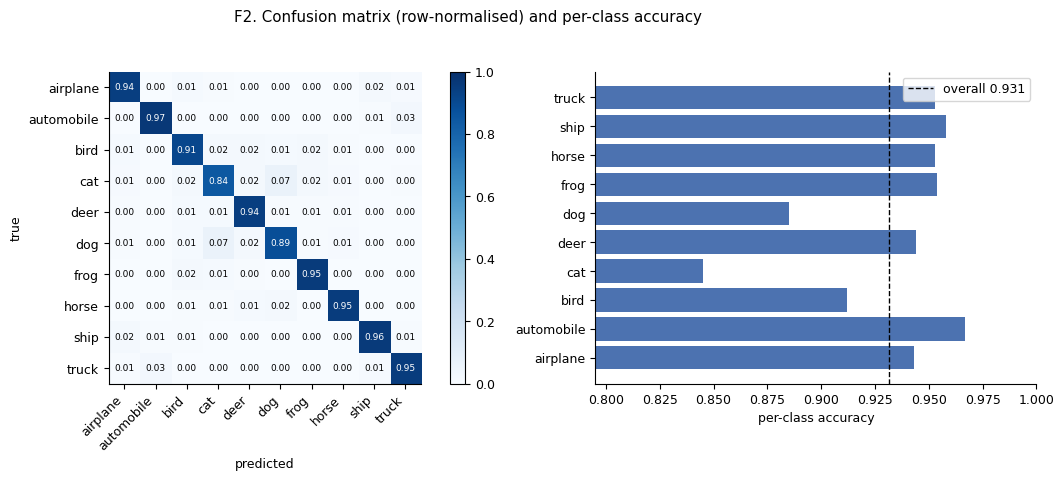

saved figure -> F2_confusion_matrix


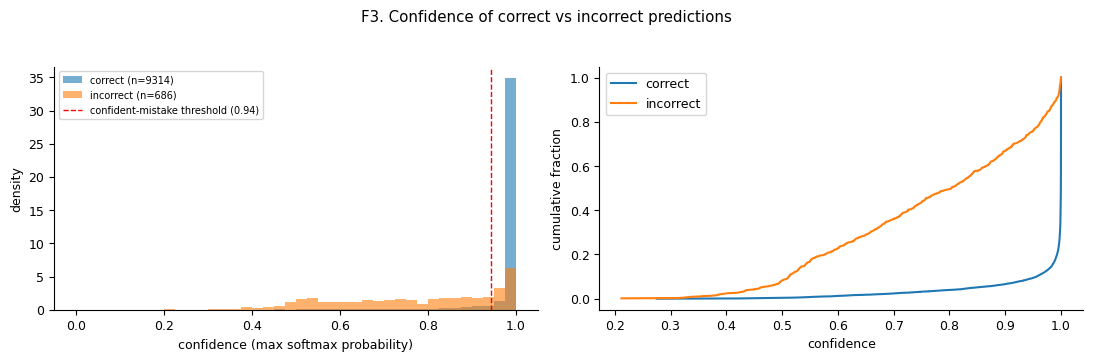

saved figure -> F3_confidence_distributions


In [ ]:
# 2.3  F2 – confusion matrix + per-class accuracy ; F3 – confidence distributions
cmat = confusion_matrix(df.true, df.pred, labels=range(10))
cm_norm = cmat / cmat.sum(1, keepdims=True).clip(min=1)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw=dict(width_ratios=[1.3, 1]))
im = ax[0].imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
for i in range(10):
    for j in range(10):
        ax[0].text(j, i, f"{cm_norm[i, j]:.2f}", ha="center", va="center", fontsize=6.5,
                   color="white" if cm_norm[i, j] > 0.5 else "black")
ax[0].set_xticks(range(10)); ax[0].set_xticklabels(CLASSES, rotation=45, ha="right")
ax[0].set_yticks(range(10)); ax[0].set_yticklabels(CLASSES)
ax[0].set_xlabel("predicted"); ax[0].set_ylabel("true"); plt.colorbar(im, ax=ax[0], fraction=0.046)
pc_acc = np.diag(cmat) / cmat.sum(1).clip(min=1)
ax[1].barh(CLASSES, pc_acc, color="#4C72B0"); ax[1].set_xlim(min(pc_acc) - 0.05, 1)
ax[1].axvline(acc, ls="--", c="k", lw=1, label=f"overall {acc:.3f}"); ax[1].legend(); ax[1].set_xlabel("per-class accuracy")
fig.suptitle("F2. Confusion matrix (row-normalised) and per-class accuracy")
savefig(fig, "F2_confusion_matrix")
RESULTS["per_class_accuracy"] = dict(zip(CLASSES, pc_acc.round(4)))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
bins = np.linspace(0, 1, 41)
ax[0].hist(df.conf[COR], bins=bins, alpha=0.6, density=True, label=f"correct (n={COR.sum()})")
ax[0].hist(df.conf[INC], bins=bins, alpha=0.6, density=True, label=f"incorrect (n={INC.sum()})")
ax[0].axvline(Q_CM, c="r", ls="--", lw=1, label=f"confident-mistake threshold ({Q_CM:.2f})")
ax[0].set_xlabel("confidence (max softmax probability)"); ax[0].set_ylabel("density"); ax[0].legend(fontsize=7)
for name, mask in [("correct", COR), ("incorrect", INC)]:
    v = np.sort(df.conf[mask].values); ax[1].plot(v, np.arange(1, len(v) + 1) / len(v), label=name)
ax[1].set_xlabel("confidence"); ax[1].set_ylabel("cumulative fraction"); ax[1].legend()
fig.suptitle("F3. Confidence of correct vs incorrect predictions")
savefig(fig, "F3_confidence_distributions")
RESULTS["frac_errors_conf_ge_0.9"] = float((df.conf[INC] >= 0.9).mean())
save_results()

**Interpretation guide (Step 2):** In F3, if many errors also have confidence near 1.0, the model is **overconfident**: confidence alone cannot flag mistakes, which motivates asking whether explanations can (RQ2). T1c lists the most common confusions; look for these in the failure cases (Step 10).

---
# STEP 3 — Generate explanations
**Why:** every later analysis uses the heatmaps. We compute them **once** and save them, so every analysis uses exactly the same maps.
**What:**
* **Grad-CAM** at layer2 (16×16), layer3 (8×8), layer4 (4×4) for the **predicted class** (all images) and for the **true class** (used for errors).
* **Vanilla gradient saliency** (|∂score/∂pixel|, max over RGB) as a second, fine-grained method.

**How Grad-CAM works (our implementation, written out so it is easy to explain in the viva):**
1. forward pass, keep the feature maps $A^k$ of the chosen layer;
2. gradient of the class score $y^c$ w.r.t. each $A^k$;
3. **global-average-pool the gradients** → channel weight $\alpha_k^c$;
4. $L^c = \mathrm{ReLU}(\sum_k \alpha_k^c A^k)$, upsampled (bilinear) to 32×32.

We store the **raw** (unscaled) maps, so all-zero maps (ReLU removed everything) can be detected. Our implementation is cross-checked against the `pytorch-grad-cam` and `captum` libraries in 3.3.

In [ ]:
# 3.1  Grad-CAM and saliency implementations
LAYER_KEYS = {"L2": "layer2", "L3": "layer3", "L4": "layer4"}
METHODS_X = ["L2", "L3", "L4", "sal"]
METH_NAME = {"L2": "Grad-CAM layer2 (16×16)", "L3": "Grad-CAM layer3 (8×8)",
             "L4": "Grad-CAM layer4 (4×4)", "sal": "Vanilla saliency", "rand": "Random patches"}

def gradcam_batch(model, x, target):
    """Grad-CAM for layer2/3/4 in ONE forward/backward pass. Returns raw maps (B,32,32) per layer."""
    acts = {}
    hooks = [getattr(model.net, name).register_forward_hook(
                 lambda mod, inp, out, k=k: acts.__setitem__(k, out))
             for k, name in LAYER_KEYS.items()]
    keys = list(LAYER_KEYS)
    try:
        with torch.enable_grad():
            logits = model(x)
            score = logits.gather(1, target.view(-1, 1)).sum()     # sum over batch: images are independent in eval mode
            grads = torch.autograd.grad(score, [acts[k] for k in keys])
    finally:
        for h in hooks: h.remove()
    cams = {}
    for k, G in zip(keys, grads):
        A = acts[k]
        w = G.mean(dim=(2, 3), keepdim=True)                         # alpha_k^c: average gradient per channel
        cam = F.relu((w * A).sum(dim=1, keepdim=True))               # weighted sum + ReLU
        cams[k] = F.interpolate(cam, size=x.shape[-2:], mode="bilinear",
                                align_corners=False)[:, 0].detach().float().cpu()
    return cams

def saliency_batch(model, x, target):
    """Vanilla gradient saliency: |d score / d pixel|, max over RGB channels."""
    x = x.clone().requires_grad_(True)
    with torch.enable_grad():
        score = model(x).gather(1, target.view(-1, 1)).sum()
        g, = torch.autograd.grad(score, x)
    return g.abs().amax(1).detach().float().cpu()

def explain(model, X, target, bs=250):
    model.eval()
    out = {k: [] for k in METHODS_X}
    for i in range(0, len(X), bs):
        x = X[i:i + bs].to(DEVICE); t = target[i:i + bs].to(DEVICE)
        cams = gradcam_batch(model, x, t)
        for k in LAYER_KEYS: out[k].append(cams[k])
        out["sal"].append(saliency_batch(model, x, t))
    return {k: torch.cat(v).numpy().astype(np.float32) for k, v in out.items()}

def load_or_compute(name, fn):
    files = {k: EXPL_DIR / f"{name}_{k}.npy" for k in METHODS_X}
    if all(f.exists() for f in files.values()):
        print(f"loaded '{name}' explanations from Drive"); return {k: np.load(f) for k, f in files.items()}
    t0 = time.time(); res = fn()
    for k, v in res.items(): np.save(files[k], v)
    print(f"computed '{name}' explanations in {time.time()-t0:.0f}s"); return res

In [ ]:
# 3.2  Compute (or load) all explanations
EXPL = load_or_compute("pred", lambda: explain(model, X_TEST, PRED_T))        # predicted class
EXPL_TRUE = load_or_compute("true", lambda: explain(model, X_TEST, TRUE_T))   # true class (used for errors)
for k in METHODS_X:
    v = EXPL[k]
    print(f"{k:>4}: shape {v.shape}, NaNs {np.isnan(v).sum()}, min {v.min():.2e}, max {v.max():.2e}, "
          f"all-zero maps {(v.reshape(len(v), -1).max(1) <= 0).sum()}")

computed 'pred' explanations in 11s


In [ ]:
# 3.3  Verification: our Grad-CAM / saliency vs the reference libraries (for the LLM-use / verification section)
n_chk = min(64, N)
xc, tc = X_TEST[:n_chk].to(DEVICE), PRED_T[:n_chk].to(DEVICE)
def _mm(a):
    a = a.reshape(len(a), -1).astype(np.float64); lo, hi = a.min(1, keepdims=True), a.max(1, keepdims=True)
    return (a - lo) / np.where(hi > lo, hi - lo, 1)
try:
    from pytorch_grad_cam import GradCAM
    from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
    with GradCAM(model=model, target_layers=[model.net.layer4[-1]]) as cam_lib:
        lib = cam_lib(input_tensor=xc, targets=[ClassifierOutputTarget(int(c)) for c in tc.cpu()])
    rho = rowwise_spearman(_mm(lib), _mm(EXPL["L4"][:n_chk]))
    RESULTS["check_gradcam_vs_library_median_spearman"] = float(np.nanmedian(rho))
    print(f"Grad-CAM (layer4) ours vs pytorch-grad-cam: median Spearman = {np.nanmedian(rho):.4f} (expect ~1.0)")
except Exception as e:
    print("pytorch-grad-cam check skipped:", repr(e))
try:
    from captum.attr import Saliency
    sal_lib = Saliency(model).attribute(xc.clone().requires_grad_(True), target=tc, abs=True)
    sal_lib = sal_lib.amax(1).detach().float().cpu().numpy()
    diff = np.abs(sal_lib - EXPL["sal"][:n_chk]).max() / (np.abs(sal_lib).max() + 1e-12)
    RESULTS["check_saliency_vs_captum_max_rel_diff"] = float(diff)
    print(f"Saliency ours vs captum: max relative difference = {diff:.2e} (expect ~0)")
except Exception as e:
    print("captum check skipped:", repr(e))
model.zero_grad(set_to_none=True)
save_results()

In [ ]:
# 3.4  F4 – qualitative grid
def norm01(m):
    m = np.asarray(m, float); return (m - m.min()) / (m.max() - m.min()) if m.max() > m.min() else np.zeros_like(m)
def show_img(ax, i):
    ax.imshow(X_TEST[i].permute(1, 2, 0).numpy(), interpolation="nearest"); ax.set_xticks([]); ax.set_yticks([])
def show_map(ax, i, m, alpha=0.55):
    show_img(ax, i); ax.imshow(norm01(m), cmap="jet", alpha=alpha, interpolation="bilinear", vmin=0, vmax=1)

rng_vis = np.random.default_rng(CFG["seed"])
def pick(mask, n):
    idx = np.where(mask)[0]; return rng_vis.choice(idx, size=min(n, len(idx)), replace=False) if len(idx) else []
sel = [("correct", i) for i in pick(COR, 4)] + [("other mistake", i) for i in pick(df.group.values == "other mistake", 4)] \
    + [("confident mistake", i) for i in pick(CM, 4)]
cols = ["image"] + [METH_NAME[k] for k in METHODS_X]
fig, axes = plt.subplots(len(sel), 5, figsize=(9.5, 1.85 * len(sel)), squeeze=False)
for r, (g, i) in enumerate(sel):
    show_img(axes[r, 0], i)
    axes[r, 0].set_ylabel(f"{g}\nT: {df.true_name[i]}\nP: {df.pred_name[i]} ({df.conf[i]:.2f})", fontsize=7)
    for c, k in enumerate(METHODS_X, start=1): show_map(axes[r, c], i, EXPL[k][i])
for c, name in enumerate(cols): axes[0, c].set_title(name, fontsize=8)
fig.suptitle("F4. Grad-CAM (three layers) and saliency for correct predictions, other mistakes and confident mistakes", y=1.0)
plt.tight_layout(); savefig(fig, "F4_qualitative_grid")

**Interpretation guide (Step 3):** L4 maps should be blob-like and roughly on the object; L2 maps sharper but noisier; saliency speckled/edge-like. Look at whether mistakes highlight the background, another object, or still the right object. This is only a **first impression**; Steps 5–8 test it quantitatively. In the report write: *"visual impressions are not evidence; we test them in Sections 4.1–4.4"*.

---
# STEP 4 — Explanation metrics
**Why:** "this map looks focused" is subjective; RQ1/RQ2 need numbers.
**What (per heatmap):**
* **Concentration (area-50)** = fraction of the image area needed to hold 50 % of the total heat. *Lower = more concentrated.* Example: 51 of 1024 pixels → 0.05 (very focused); 400 pixels → 0.39 (spread out).
* **Normalised entropy** of the map treated as a probability distribution (0 = all heat in one pixel, 1 = uniform).
* **All-zero flag** – Grad-CAM gives no explanation at all (ReLU removed everything). These maps are excluded from the concentration analysis but **counted and reported**.

Two metrics are used so that conclusions do not depend on one definition.

In [ ]:
# 4.1  Metrics for every map
def area50(flat, mass=0.5):
    flat = np.asarray(flat, np.float64); tot = flat.sum(1)
    s = -np.sort(-flat, axis=1)                                   # pixels sorted high -> low
    cum = np.cumsum(s, 1) / np.where(tot > 0, tot, 1)[:, None]
    k = (cum < mass - 1e-12).sum(1) + 1                           # number of pixels needed to reach 50%
    out = k / flat.shape[1]; out[tot <= 0] = np.nan; return out

def norm_entropy(flat):
    flat = np.asarray(flat, np.float64); tot = flat.sum(1)
    p = flat / np.where(tot > 0, tot, 1)[:, None]
    plogp = np.where(p > 0, p * np.log(np.where(p > 0, p, 1)), 0.0)
    h = -plogp.sum(1) / np.log(flat.shape[1]); h[tot <= 0] = np.nan; return h

for k in METHODS_X:
    flat = EXPL[k].reshape(N, -1)
    df[f"zero_{k}"] = flat.max(1) <= 0
    df[f"area50_{k}"] = area50(flat)
    df[f"entropy_{k}"] = norm_entropy(flat)
df.to_csv(RES / "predictions.csv", index=False)

zero_rows = []
for k in METHODS_X:
    z = df[f"zero_{k}"].values
    zero_rows.append({"Method": METH_NAME[k], "All-zero maps (n)": int(z.sum()),
                      "% of correct": round(100 * z[COR].mean(), 2), "% of incorrect": round(100 * z[INC].mean(), 2),
                      "% of confident mistakes": round(100 * z[CM].mean(), 2) if CM.sum() else np.nan})
T1b = save_table(pd.DataFrame(zero_rows), "T1b_all_zero_maps")
RESULTS["all_zero_maps"] = {r["Method"]: r["All-zero maps (n)"] for r in zero_rows}

In [ ]:
# 4.2  Metric distributions (appendix figure)
fig, axes = plt.subplots(2, 4, figsize=(15, 5.5))
for c, k in enumerate(METHODS_X):
    for r, metric in enumerate(["area50", "entropy"]):
        ax = axes[r, c]
        for name, mask in [("correct", COR), ("incorrect", INC)]:
            ax.hist(df.loc[mask, f"{metric}_{k}"].dropna(), bins=40, alpha=0.55, density=True, label=name)
        ax.set_title(f"{METH_NAME[k]} – {metric}", fontsize=8)
        if c == 0: ax.set_ylabel("density")
axes[0, 0].legend()
fig.suptitle("F4b. Distributions of concentration (area-50, lower = more concentrated) and normalised entropy")
plt.tight_layout(); savefig(fig, "F4b_metric_distributions")

---
# STEP 5 — RQ1 & RQ2: do explanations reflect correctness?
**Why:** first half of the title question. If maps look the same for mistakes, a focused heatmap gives **false reassurance**.

| Analysis | Test | Why this test |
|---|---|---|
| RQ1/H1: correct vs incorrect | Mann–Whitney U + rank-biserial **r** + bootstrap CI of median difference | metrics are skewed, groups independent; with thousands of images every tiny difference is "significant", so the **effect size** matters |
| RQ2/H2: detect confident mistakes | **AUROC** (+ bootstrap CI), compared with **confidence** as reference | AUROC = probability that a random mistake has a less concentrated map than a random correct image (0.5 = chance) |
| RQ2: confidence vs concentration within errors | Spearman ρ | monotonic relation, no normality assumption |
| Per-class control | r per true class + class-adjusted r | rules out **Simpson's paradox** (class difficulty driving the overall effect) |
| Predicted- vs true-class map (errors) | Spearman between the two maps | "right place, wrong reading" vs "wrong place" |

Sign convention: **r = P(incorrect > correct) − P(incorrect < correct)**. H1 predicts **r > 0** (mistakes have larger area-50, i.e. less concentrated maps). All p-values are **Holm-corrected**.

In [ ]:
# 5.1  T2 – RQ1 / RQ2 statistics
def arr(col, mask):
    v = df.loc[mask, col].values.astype(float); return v[~np.isnan(v)]
def auc_groups(score, pos, neg):
    score = np.asarray(score, float)
    y = np.r_[np.ones(pos.sum()), np.zeros(neg.sum())]; s = np.r_[score[pos], score[neg]]
    return auroc_ci(y, s)

rows = []
for k in METHODS_X:
    for metric in ["area50", "entropy"]:
        col = f"{metric}_{k}"; s = df[col].values.astype(float)
        a_c, a_i, a_cm = arr(col, COR), arr(col, INC), arr(col, CM)
        r, p = rb_ind(a_i, a_c)
        lo, hi = boot_ci(lambda a, b: np.median(a) - np.median(b), [a_i, a_c])
        au_cm, au_inc = auc_groups(s, CM, COR), auc_groups(s, INC, COR)
        rows.append(dict(method=k, metric=metric, n_correct=len(a_c), n_incorrect=len(a_i), n_cm=len(a_cm),
                         med_correct=np.median(a_c), med_incorrect=np.median(a_i),
                         med_cm=np.median(a_cm) if len(a_cm) else np.nan,
                         diff=np.median(a_i) - np.median(a_c), diff_lo=lo, diff_hi=hi, r=r, p=p,
                         auroc_cm=au_cm[0], auroc_cm_lo=au_cm[1], auroc_cm_hi=au_cm[2],
                         auroc_inc=au_inc[0], auroc_inc_lo=au_inc[1], auroc_inc_hi=au_inc[2]))
T2_raw = pd.DataFrame(rows)
T2_raw["p_holm"] = holm(T2_raw.p)
T2_raw["H1"] = [verdict(r, p, +1) for r, p in zip(T2_raw.r, T2_raw.p_holm)]
CONF_AU_CM = auc_groups(-df.conf.values, CM, COR)
CONF_AU_INC = auc_groups(-df.conf.values, INC, COR)
save_table(T2_raw, "T2_rq1_rq2_raw", show=False)

T2 = pd.DataFrame({
    "Method": T2_raw.method.map(METH_NAME), "Metric": T2_raw.metric,
    "Median correct": T2_raw.med_correct.round(3), "Median incorrect": T2_raw.med_incorrect.round(3),
    "Median conf. mistake": T2_raw.med_cm.round(3),
    "Δ median (inc−cor) [95% CI]": [fmt_ci(a, b, c) for a, b, c in zip(T2_raw["diff"], T2_raw.diff_lo, T2_raw.diff_hi)],
    "r (inc vs cor)": T2_raw.r.round(3), "p (Holm)": T2_raw.p_holm.map(lambda v: f"{v:.2e}"), "H1": T2_raw.H1,
    "AUROC conf.mistake vs correct": [fmt_ci(a, b, c) for a, b, c in zip(T2_raw.auroc_cm, T2_raw.auroc_cm_lo, T2_raw.auroc_cm_hi)],
    "AUROC incorrect vs correct": [fmt_ci(a, b, c) for a, b, c in zip(T2_raw.auroc_inc, T2_raw.auroc_inc_lo, T2_raw.auroc_inc_hi)],
})
ref = pd.DataFrame([{"Method": "Confidence (reference, score = −confidence)", "Metric": "—",
                     "AUROC conf.mistake vs correct": fmt_ci(*CONF_AU_CM), "AUROC incorrect vs correct": fmt_ci(*CONF_AU_INC)}])
T2 = save_table(pd.concat([T2, ref], ignore_index=True).fillna(""), "T2_rq1_rq2")

RESULTS["RQ1_RQ2"] = {f"{r.method}_{r.metric}": dict(r=r.r, p_holm=r.p_holm, H1=r.H1, auroc_cm=r.auroc_cm,
                      auroc_cm_ci=[r.auroc_cm_lo, r.auroc_cm_hi], auroc_inc=r.auroc_inc) for r in T2_raw.itertuples()}
RESULTS["RQ2_confidence_auroc_cm"] = CONF_AU_CM
RESULTS["RQ2_confidence_auroc_inc"] = CONF_AU_INC
save_results()

saved table -> T2_rq1_rq2_raw


,Method,Metric,Median correct,Median incorrect,Median conf. mistake,Δ median (inc−cor) [95% CI],r (inc vs cor),p (Holm),H1,AUROC conf.mistake vs correct,AUROC incorrect vs correct
0,Grad-CAM layer2 (16×16),area50,0.25,0.194,0.222,"-0.056 [-0.069, -0.045]",-0.292,6.91e-37,✗ opposite direction,"0.428 [0.386, 0.467]","0.354 [0.335, 0.375]"
1,Grad-CAM layer2 (16×16),entropy,0.958,0.93,0.947,"-0.029 [-0.033, -0.021]",-0.297,4.38e-38,✗ opposite direction,"0.427 [0.388, 0.466]","0.351 [0.333, 0.370]"
2,Grad-CAM layer3 (8×8),area50,0.076,0.142,0.136,"0.065 [0.055, 0.076]",0.405,1.30e-68,✓ supported,"0.671 [0.628, 0.706]","0.703 [0.685, 0.720]"
3,Grad-CAM layer3 (8×8),entropy,0.812,0.894,0.89,"0.082 [0.073, 0.091]",0.407,2.42e-69,✓ supported,"0.670 [0.631, 0.708]","0.704 [0.685, 0.722]"
4,Grad-CAM layer4 (4×4),area50,0.403,0.381,0.393,"-0.022 [-0.025, -0.019]",-0.393,9.06e-66,✗ opposite direction,"0.390 [0.348, 0.430]","0.303 [0.283, 0.324]"
5,Grad-CAM layer4 (4×4),entropy,0.996,0.993,0.995,"-0.003 [-0.003, -0.002]",-0.395,4.49e-66,✗ opposite direction,"0.392 [0.353, 0.433]","0.303 [0.283, 0.324]"
6,Vanilla saliency,area50,0.215,0.207,0.208,"-0.008 [-0.010, -0.006]",-0.189,1.22e-16,✗ opposite direction,"0.401 [0.358, 0.441]","0.405 [0.383, 0.427]"
7,Vanilla saliency,entropy,0.954,0.951,0.951,"-0.003 [-0.004, -0.002]",-0.196,1.89e-17,✗ opposite direction,"0.394 [0.355, 0.430]","0.402 [0.380, 0.423]"
8,"Confidence (reference, score = −confidence)",—,,,,,,,,"0.799 [0.780, 0.817]","0.927 [0.918, 0.934]"


saved table -> T2_rq1_rq2


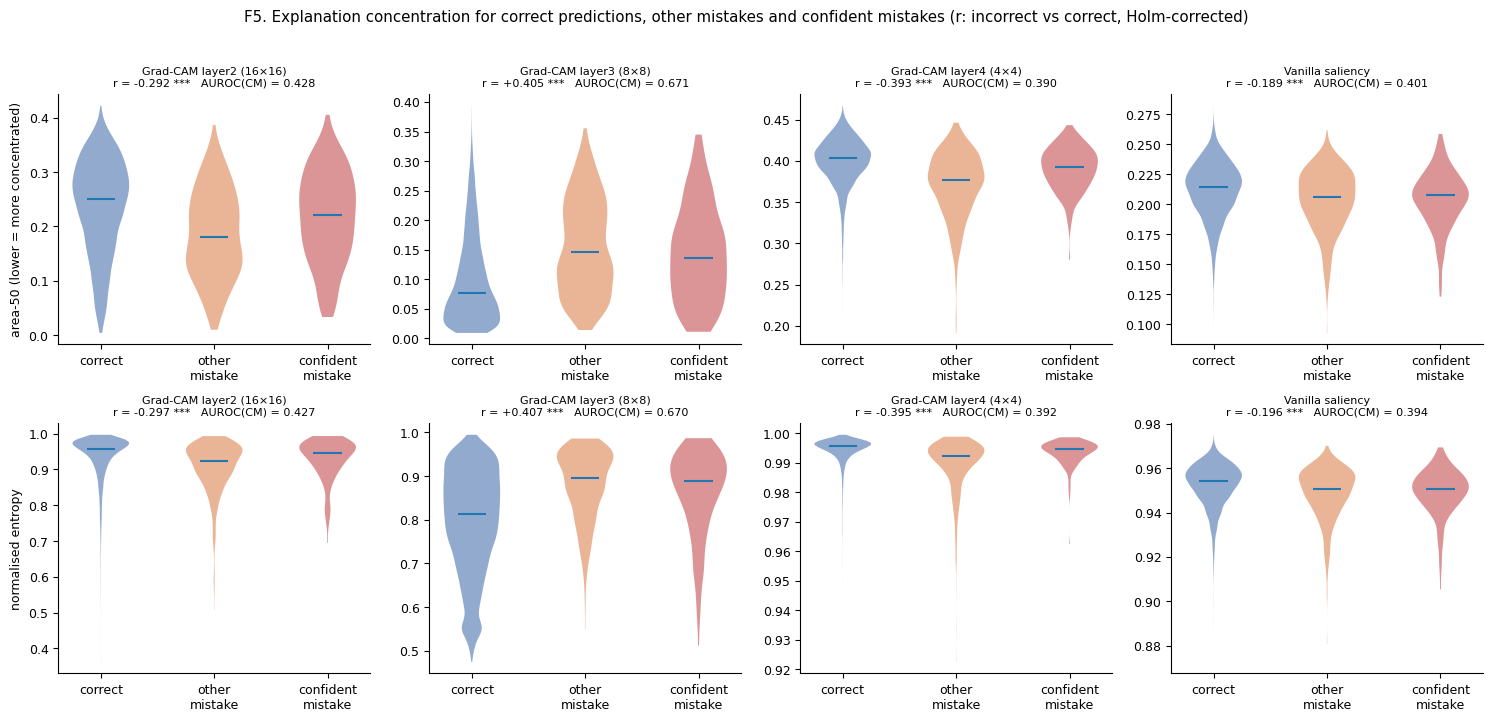

saved figure -> F5_concentration_by_group


In [ ]:
# 5.2  F5 – concentration by group (violins)
GN = ["correct", "other mistake", "confident mistake"]; GC = ["#4C72B0", "#DD8452", "#C44E52"]
fig, axes = plt.subplots(2, 4, figsize=(15, 7))
for c, k in enumerate(METHODS_X):
    for r_, metric in enumerate(["area50", "entropy"]):
        ax = axes[r_, c]
        data = [df.loc[df.group == g, f"{metric}_{k}"].dropna().values for g in GN]
        data = [d if len(d) > 1 else np.array([np.nan, np.nan]) for d in data]
        ok = [i for i, d in enumerate(data) if not np.isnan(d).all()]
        parts = ax.violinplot([data[i] for i in ok], positions=[i + 1 for i in ok], showmedians=True, showextrema=False)
        for pc, i in zip(parts["bodies"], ok): pc.set_facecolor(GC[i]); pc.set_alpha(0.6)
        ax.set_xticks([1, 2, 3]); ax.set_xticklabels(["correct", "other\nmistake", "confident\nmistake"])
        row = T2_raw[(T2_raw.method == k) & (T2_raw.metric == metric)].iloc[0]
        ax.set_title(f"{METH_NAME[k]}\nr = {row.r:+.3f} {stars(row.p_holm)}   AUROC(CM) = {row.auroc_cm:.3f}", fontsize=8)
        if c == 0: ax.set_ylabel("area-50 (lower = more concentrated)" if metric == "area50" else "normalised entropy")
fig.suptitle("F5. Explanation concentration for correct predictions, other mistakes and confident mistakes "
             "(r: incorrect vs correct, Holm-corrected)")
plt.tight_layout(); savefig(fig, "F5_concentration_by_group")

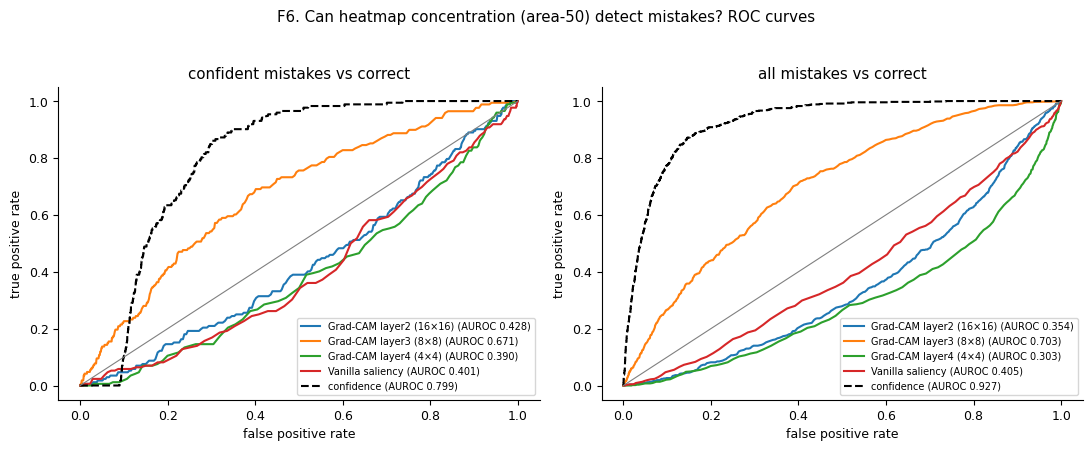

saved figure -> F6_roc_mistake_detection


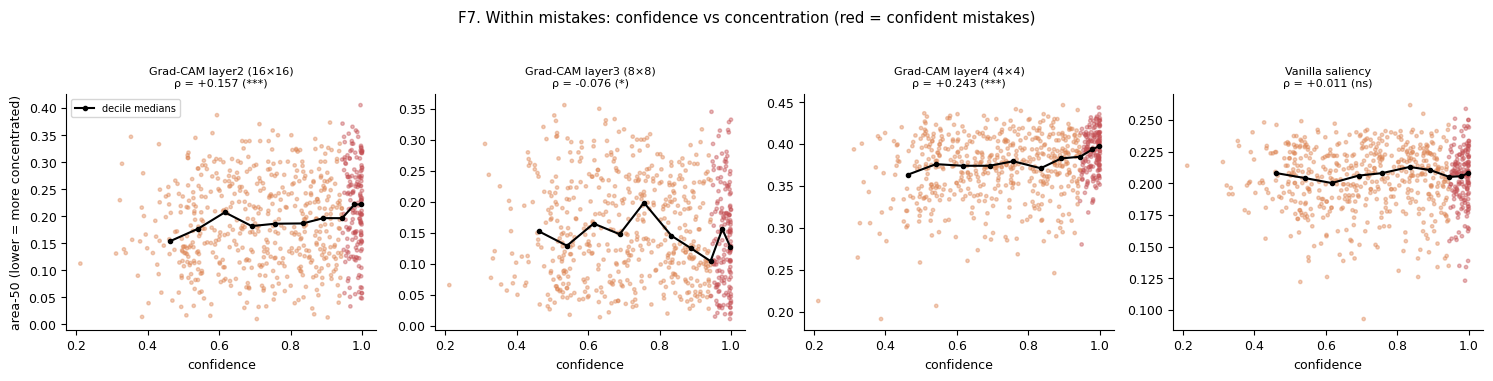

saved figure -> F7_confidence_vs_concentration


,Method,n errors,"Spearman ρ (conf, area-50)",p,p (Holm)
0,Grad-CAM layer2 (16×16),686,0.157,3.480620e-05,1.044186e-04
1,Grad-CAM layer3 (8×8),681,-0.076,4.752190e-02,9.504380e-02
2,Grad-CAM layer4 (4×4),686,0.243,1.150219e-10,4.600875e-10
3,Vanilla saliency,686,0.011,7.736353e-01,7.736353e-01


saved table -> T2b_spearman_conf_concentration


In [ ]:
# 5.3  F6 – ROC curves ; F7 – confidence vs concentration within errors
def roc_xy(score, pos, neg):
    score = np.asarray(score, float)
    y = np.r_[np.ones(pos.sum()), np.zeros(neg.sum())]; s = np.r_[score[pos], score[neg]]
    ok = ~np.isnan(s); fpr, tpr, _ = roc_curve(y[ok], s[ok]); return fpr, tpr

fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
for ax, (pos, title, conf_au) in zip(axes, [(CM, "confident mistakes vs correct", CONF_AU_CM),
                                             (INC, "all mistakes vs correct", CONF_AU_INC)]):
    for k in METHODS_X:
        fpr, tpr = roc_xy(df[f"area50_{k}"].values, pos, COR)
        au = auc_groups(df[f"area50_{k}"].values, pos, COR)[0]
        ax.plot(fpr, tpr, label=f"{METH_NAME[k]} (AUROC {au:.3f})")
    fpr, tpr = roc_xy(-df.conf.values, pos, COR)
    ax.plot(fpr, tpr, "k--", label=f"confidence (AUROC {conf_au[0]:.3f})")
    ax.plot([0, 1], [0, 1], c="grey", lw=0.8)
    ax.set_xlabel("false positive rate"); ax.set_ylabel("true positive rate"); ax.set_title(title); ax.legend(fontsize=7)
fig.suptitle("F6. Can heatmap concentration (area-50) detect mistakes? ROC curves")
savefig(fig, "F6_roc_mistake_detection")

sp_rows = []
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6), sharey=False)
for ax, k in zip(axes, METHODS_X):
    sub = df[INC & df[f"area50_{k}"].notna().values]
    rho, p = stats.spearmanr(sub.conf, sub[f"area50_{k}"]) if len(sub) > 2 else (np.nan, np.nan)
    sp_rows.append({"Method": METH_NAME[k], "n errors": len(sub), "Spearman ρ (conf, area-50)": round(rho, 3), "p": p})
    ax.scatter(sub.conf, sub[f"area50_{k}"], s=6, alpha=0.4, c=np.where(sub.cm, "#C44E52", "#DD8452"))
    if len(sub) > 20:
        qb = pd.qcut(sub.conf, 10, duplicates="drop")
        med = sub.groupby(qb, observed=True).agg(c=("conf", "median"), a=(f"area50_{k}", "median"))
        ax.plot(med.c, med.a, "k-o", ms=3, lw=1.5, label="decile medians")
    ax.set_title(f"{METH_NAME[k]}\nρ = {rho:+.3f} ({stars(p)})", fontsize=8); ax.set_xlabel("confidence")
axes[0].set_ylabel("area-50 (lower = more concentrated)"); axes[0].legend(fontsize=7)
fig.suptitle("F7. Within mistakes: confidence vs concentration (red = confident mistakes)")
plt.tight_layout(); savefig(fig, "F7_confidence_vs_concentration")
T2b = pd.DataFrame(sp_rows); T2b["p (Holm)"] = holm(T2b.p); save_table(T2b, "T2b_spearman_conf_concentration")
RESULTS["RQ2_spearman_within_errors"] = {r["Method"]: r["Spearman ρ (conf, area-50)"] for r in sp_rows}
save_results()

In [ ]:
# 5.4  F8 – per-class control (Simpson's paradox check)
pc_rows, adj_rows = [], []
fig, axes = plt.subplots(1, 4, figsize=(15, 4.2), sharey=True)
for ax, k in zip(axes, METHODS_X):
    col = f"area50_{k}"
    for c in range(10):
        m_c = df.true.values == c
        a_i, a_c = arr(col, m_c & INC), arr(col, m_c & COR)
        if len(a_i) >= 5 and len(a_c) >= 5:
            r, p = rb_ind(a_i, a_c)
            lo, hi = boot_ci(lambda a, b: rb_ind(a, b)[0], [a_i, a_c], B=max(100, CFG["n_boot"] // 4))
        else:
            r = p = lo = hi = np.nan
        pc_rows.append(dict(method=k, cls=CLASSES[c], n_inc=len(a_i), n_cor=len(a_c), r=r, lo=lo, hi=hi, p=p))
    # class-adjusted: percentile rank of the metric WITHIN each true class, then compare
    pr = df.groupby("true")[col].rank(pct=True).values
    r_adj, p_adj = rb_ind(pr[INC], pr[COR])
    r_all = T2_raw[(T2_raw.method == k) & (T2_raw.metric == "area50")].r.iloc[0]
    adj_rows.append({"Method": METH_NAME[k], "r overall": round(r_all, 3), "r class-adjusted": round(r_adj, 3), "p class-adjusted": p_adj})
    sub = pd.DataFrame([x for x in pc_rows if x["method"] == k])
    y = np.arange(10)
    ax.errorbar(sub.r, y, xerr=[sub.r - sub.lo, sub.hi - sub.r], fmt="o", c="#4C72B0", capsize=2)
    ax.axvline(0, c="grey", lw=0.8); ax.axvline(r_all, c="k", ls="--", lw=1, label=f"overall r={r_all:+.2f}")
    ax.axvline(r_adj, c="r", ls=":", lw=1.2, label=f"class-adjusted r={r_adj:+.2f}")
    ax.set_yticks(y); ax.set_yticklabels(CLASSES); ax.set_title(METH_NAME[k], fontsize=8); ax.set_xlabel("r (incorrect vs correct)")
    ax.legend(fontsize=7)
fig.suptitle("F8. Per-class effect sizes for concentration (area-50); r > 0 = mistakes less concentrated")
plt.tight_layout(); savefig(fig, "F8_per_class_effects")
T2c = pd.DataFrame(pc_rows); save_table(T2c.round(3), "T2c_per_class", show=False)
T2d = pd.DataFrame(adj_rows); T2d["p class-adjusted (Holm)"] = holm(T2d["p class-adjusted"]); save_table(T2d, "T2d_class_adjusted")
RESULTS["RQ1_class_adjusted"] = {r["Method"]: r["r class-adjusted"] for r in adj_rows}
save_results()

In [ ]:
# 5.5  F9 – predicted-class vs true-class Grad-CAM for mistakes
err_idx = np.where(INC)[0]
SIM_PT = {k: rowwise_spearman(EXPL[k][err_idx].reshape(len(err_idx), -1),
                              EXPL_TRUE[k][err_idx].reshape(len(err_idx), -1)) for k in METHODS_X}
fig, axes = plt.subplots(1, 4, figsize=(15, 3.2), sharey=True)
pt_rows = []
for ax, k in zip(axes, METHODS_X):
    v = SIM_PT[k][~np.isnan(SIM_PT[k])]
    ax.hist(v, bins=30, color="#55A868", alpha=0.8); ax.axvline(np.median(v) if len(v) else 0, c="k", ls="--")
    ax.set_title(f"{METH_NAME[k]}\nmedian ρ = {np.median(v) if len(v) else np.nan:.3f}", fontsize=8)
    ax.set_xlabel("Spearman ρ (pred-class map, true-class map)")
    pt_rows.append({"Method": METH_NAME[k], "n": len(v), "median ρ": round(np.median(v), 3) if len(v) else np.nan,
                    "% with ρ > 0.8 (same region)": round(100 * (v > 0.8).mean(), 1) if len(v) else np.nan,
                    "% with ρ < 0.2 (different region)": round(100 * (v < 0.2).mean(), 1) if len(v) else np.nan})
axes[0].set_ylabel("number of mistakes")
fig.suptitle("F9a. For mistakes: does the model look at the same region for the predicted and the true class?")
plt.tight_layout(); savefig(fig, "F9a_pred_vs_true_map_similarity")
save_table(pd.DataFrame(pt_rows), "T2e_pred_vs_true_similarity")

s4 = SIM_PT["L4"]; ok = np.where(~np.isnan(s4))[0]
if len(ok) >= 6:
    order = ok[np.argsort(s4[ok])]
    ex = [(err_idx[i], s4[i], "different region") for i in order[:3]] + [(err_idx[i], s4[i], "same region") for i in order[-3:]]
    fig, axes = plt.subplots(2, 9, figsize=(15, 3.8))
    for j, (i, rho, lab) in enumerate(ex):
        r_, c0 = divmod(j, 3); c0 *= 3
        show_img(axes[r_, c0], i); axes[r_, c0].set_title(f"T:{df.true_name[i]} P:{df.pred_name[i]}\n{lab}, ρ={rho:.2f}", fontsize=7)
        show_map(axes[r_, c0 + 1], i, EXPL["L4"][i]); axes[r_, c0 + 1].set_title("map for PREDICTED", fontsize=7)
        show_map(axes[r_, c0 + 2], i, EXPL_TRUE["L4"][i]); axes[r_, c0 + 2].set_title("map for TRUE", fontsize=7)
    fig.suptitle("F9b. Examples (Grad-CAM layer4): top = model looked at different regions; bottom = same region, wrong class")
    plt.tight_layout(); savefig(fig, "F9b_pred_vs_true_examples")
RESULTS["pred_vs_true_median_rho"] = {r["Method"]: r["median ρ"] for r in pt_rows}
save_results()

**Interpretation guide (Step 5):**

| What you see | Meaning |
|---|---|
| H1 ✓ with \|r\| ≥ 0.3 | concentration clearly differs → Grad-CAM carries some correctness signal |
| H1 ✓ but \|r\| < 0.1 | significant only because n is large → practically negligible |
| H1 ✗ (not significant) | map shape is independent of correctness → focused maps give no assurance |
| r < 0 (opposite) | mistakes are *more* concentrated → model latches onto a single misleading feature (check F14) |
| AUROC (concentration) close to 0.5 and below the confidence AUROC | H2 supported: explanations add little for detecting confident mistakes |
| class-adjusted r ≪ overall r (F8, T2d) | the overall effect is partly a **class confound** (Simpson's paradox) |
| high ρ in F9 | "right place, wrong reading" (look-alike classes); low ρ → "looked somewhere else" |

Always report effect size + CI, not only p-values.

---
# STEP 6 — Sanity check (model-parameter randomisation, Adebayo et al. 2018)
**Why:** some saliency methods produce nearly the same map for a model with **random weights**, which means they behave like edge detectors rather than explanations. Before trusting any result, we check that our maps depend on what the model **learned**.
**What:** cascading randomisation from the top: fc → layer4 → layer3 → layer2 → layer1 → stem (conv1+bn1). After each stage we recompute all maps (same target class as the trained model) and measure similarity to the trained-model maps with **Spearman ρ** and **SSIM**.
**Expected:** similarity drops quickly → method **passes**. Similarity stays high → method **fails** (map reflects image structure, not the model).

In [ ]:
# 6.1  Cascading randomisation
rng_s = np.random.default_rng(CFG["seed"] + 1)
err_i, cor_i = np.where(INC)[0], np.where(COR)[0]
n_s = min(CFG["sanity_n"], N); n_e = min(len(err_i), n_s // 2)
S_IDX = np.sort(np.concatenate([rng_s.choice(err_i, n_e, replace=False), rng_s.choice(cor_i, n_s - n_e, replace=False)]))
Xs, ts = X_TEST[S_IDX], PRED_T[S_IDX]
STAGES = [("trained", []), ("fc", ["fc"]), ("layer4", ["layer4"]), ("layer3", ["layer3"]),
          ("layer2", ["layer2"]), ("layer1", ["layer1"]), ("stem", ["conv1", "bn1"])]
SAN_FILE = RES / "sanity_maps.npz"
if SAN_FILE.exists() and np.array_equal(np.load(SAN_FILE)["S_IDX"], S_IDX):
    z = np.load(SAN_FILE); STAGE_MAPS = {s: {k: z[f"{s}__{k}"] for k in METHODS_X} for s, _ in STAGES}
    print("loaded sanity-check maps from Drive")
else:
    rand_model = copy.deepcopy(model); STAGE_MAPS = {}
    for s_i, (stage, mods) in enumerate(STAGES):
        for name in mods:
            torch.manual_seed(CFG["seed"] + 1000 + s_i)
            for m in getattr(rand_model.net, name).modules():
                if hasattr(m, "reset_parameters"): m.reset_parameters()
        rand_model.eval()
        STAGE_MAPS[stage] = {k: EXPL[k][S_IDX] for k in METHODS_X} if s_i == 0 else explain(rand_model, Xs, ts)
        print("stage done:", stage)
    np.savez_compressed(SAN_FILE, S_IDX=S_IDX, **{f"{s}__{k}": v for s, d in STAGE_MAPS.items() for k, v in d.items()})
    del rand_model

def ssim_rows(A, B):
    out = np.full(len(A), np.nan)
    for i in range(len(A)):
        a, b = A[i].astype(np.float64), B[i].astype(np.float64)
        if a.max() <= a.min() or b.max() <= b.min(): continue
        out[i] = structural_similarity(norm01(a), norm01(b), data_range=1.0)
    return out

san_rows, SAN = [], {}
for k in METHODS_X:
    base = STAGE_MAPS["trained"][k]
    for stage, _ in STAGES:
        cur = STAGE_MAPS[stage][k]
        rho = rowwise_spearman(base.reshape(len(base), -1), cur.reshape(len(cur), -1))
        ss = ssim_rows(base, cur); SAN[(k, stage)] = (rho, ss)
        san_rows.append({"Method": METH_NAME[k], "Randomised up to": stage,
                         "Spearman median": np.nanmedian(rho), "Spearman Q1": np.nanpercentile(rho, 25), "Spearman Q3": np.nanpercentile(rho, 75),
                         "SSIM median": np.nanmedian(ss), "SSIM Q1": np.nanpercentile(ss, 25), "SSIM Q3": np.nanpercentile(ss, 75),
                         "% undefined (constant map)": round(100 * np.isnan(rho).mean(), 1)})
T3 = save_table(pd.DataFrame(san_rows).round(3), "T3_sanity_check")
RESULTS["sanity_full_randomisation_median_spearman"] = {METH_NAME[k]: float(np.nanmedian(SAN[(k, "stem")][0])) for k in METHODS_X}
save_results()

stage done: trained
stage done: fc
stage done: layer4
stage done: layer3
stage done: layer2
stage done: layer1
stage done: stem


,Method,Randomised up to,Spearman median,Spearman Q1,Spearman Q3,SSIM median,SSIM Q1,SSIM Q3,% undefined (constant map)
0,Grad-CAM layer2 (16×16),trained,1.000,1.000,1.000,1.000,1.000,1.000,0.0
1,Grad-CAM layer2 (16×16),fc,0.208,-0.225,0.584,0.117,-0.046,0.429,0.4
2,Grad-CAM layer2 (16×16),layer4,0.061,-0.162,0.285,0.054,-0.050,0.197,0.1
3,Grad-CAM layer2 (16×16),layer3,-0.067,-0.210,0.082,-0.000,-0.046,0.052,0.0
4,Grad-CAM layer2 (16×16),layer2,0.010,-0.110,0.117,0.015,-0.019,0.071,4.4
5,Grad-CAM layer2 (16×16),layer1,-0.006,-0.155,0.127,0.008,-0.025,0.064,23.3
6,Grad-CAM layer2 (16×16),stem,-0.007,-0.129,0.132,0.013,-0.026,0.071,16.1
7,Grad-CAM layer3 (8×8),trained,1.000,1.000,1.000,1.000,1.000,1.000,4.0
8,Grad-CAM layer3 (8×8),fc,0.164,-0.172,0.458,0.125,-0.006,0.339,6.9
9,Grad-CAM layer3 (8×8),layer4,0.036,-0.153,0.210,0.049,-0.015,0.129,4.0


saved table -> T3_sanity_check


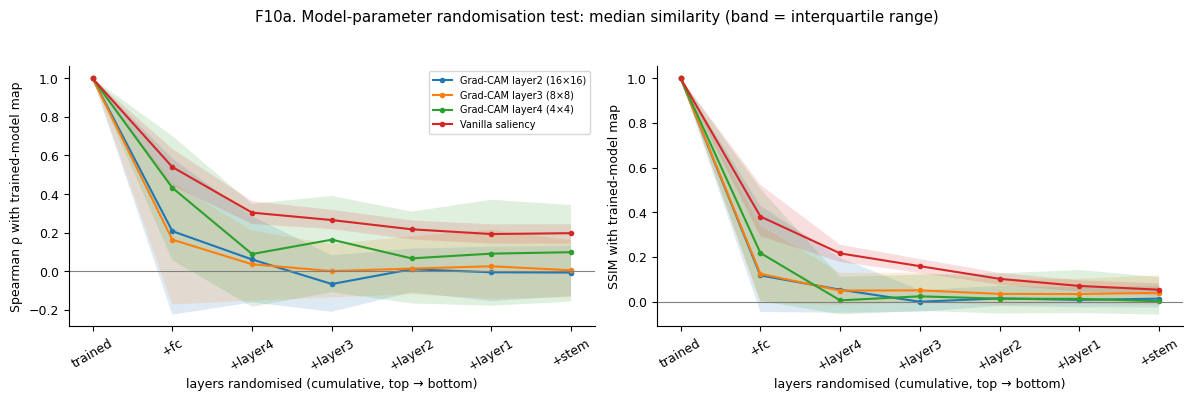

saved figure -> F10a_sanity_curves


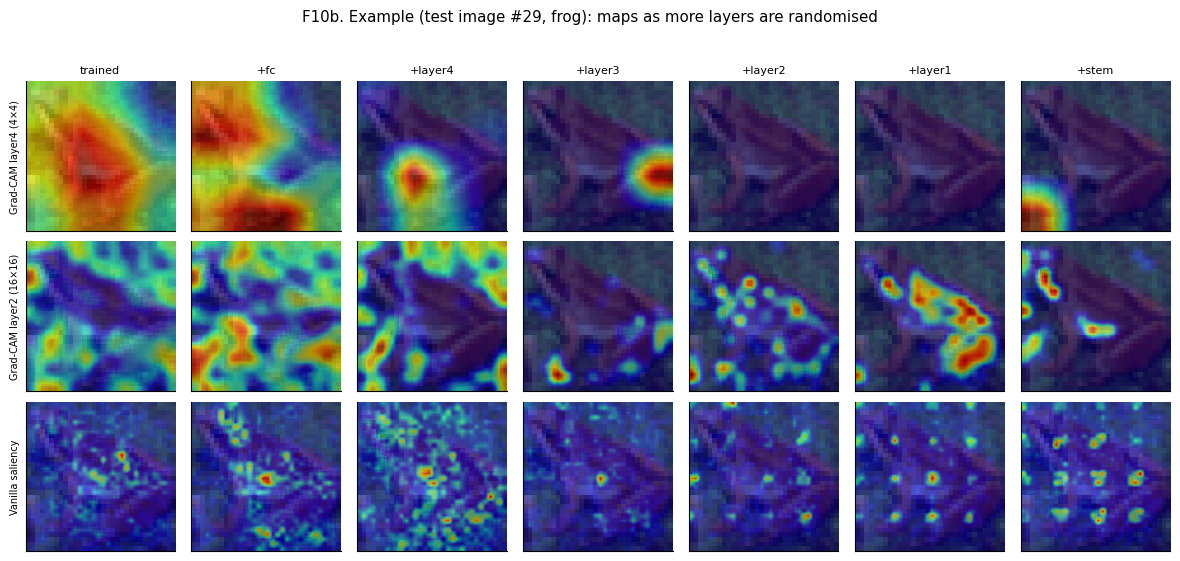

saved figure -> F10b_sanity_examples


In [ ]:
# 6.2  F10 – sanity-check curves and example maps
xs = np.arange(len(STAGES)); labels = [s for s, _ in STAGES]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for j, (ax, nm) in enumerate(zip(axes, ["Spearman ρ", "SSIM"])):
    for k in METHODS_X:
        med = [np.nanmedian(SAN[(k, s)][j]) for s in labels]
        q1 = [np.nanpercentile(SAN[(k, s)][j], 25) for s in labels]; q3 = [np.nanpercentile(SAN[(k, s)][j], 75) for s in labels]
        ax.plot(xs, med, "-o", ms=3, label=METH_NAME[k]); ax.fill_between(xs, q1, q3, alpha=0.15)
    ax.set_xticks(xs); ax.set_xticklabels(["trained"] + [f"+{s}" for s in labels[1:]], rotation=30)
    ax.axhline(0, c="grey", lw=0.8); ax.set_ylabel(f"{nm} with trained-model map"); ax.set_xlabel("layers randomised (cumulative, top → bottom)")
axes[0].legend(fontsize=7)
fig.suptitle("F10a. Model-parameter randomisation test: median similarity (band = interquartile range)")
plt.tight_layout(); savefig(fig, "F10a_sanity_curves")

ex_pos = next((j for j in range(len(S_IDX)) if all(STAGE_MAPS["trained"][k][j].max() > 0 for k in METHODS_X)), 0)
i_img = S_IDX[ex_pos]
fig, axes = plt.subplots(3, len(STAGES), figsize=(1.7 * len(STAGES), 5.4), squeeze=False)
for r_, k in enumerate(["L4", "L2", "sal"]):
    for c_, s in enumerate(labels):
        show_map(axes[r_, c_], i_img, STAGE_MAPS[s][k][ex_pos])
        if r_ == 0: axes[r_, c_].set_title("trained" if c_ == 0 else f"+{s}", fontsize=8)
    axes[r_, 0].set_ylabel(METH_NAME[k], fontsize=7)
fig.suptitle(f"F10b. Example (test image #{i_img}, {df.true_name[i_img]}): maps as more layers are randomised")
plt.tight_layout(); savefig(fig, "F10b_sanity_examples")

**Interpretation guide (Step 6):** Grad-CAM is expected to drop quickly (its channel weights come from the class gradient, which is destroyed). Vanilla saliency may stay partly similar (keeps edge structure). If a method keeps a high similarity, write that results based on it must be treated with caution. Q: *what if a method passes this test but fails the deletion test?* → it depends on the model, but it does not point to the pixels the model actually needs.

---
# STEP 7 — RQ3: deletion experiment (core experiment)
**Why:** RQ1–RQ2 ask whether maps *look* different; RQ3 asks whether the highlighted pixels are actually **important to the model**. We **intervene** on the input (delete pixels) and measure the effect: a causal test of faithfulness.

**How:**
* For each image and method, pixels are ranked (most important first; random tie-break with a fixed seed). At level *k* the top *k* % are deleted, *k* = 0, 5, …, 50 %.
* **Random baseline:** random **contiguous** 4×4 patches placed one after another (5 independent draws per image, averaged). Contiguous, because Grad-CAM regions are blobs; scattered random pixels would differ in *shape* as well as *location*. Masks are **nested** (what is deleted at 5 % stays deleted at 10 %).
* **Three deletion values:** black, dataset mean colour, Gaussian blur (σ = 2). Each produces a different out-of-distribution artefact (Hooker et al. 2019); if the conclusion holds for all three, it is robust to that problem.
* We record the softmax probability of the **originally predicted class** → a deletion curve per image. Summary: **AUC** of the curve (x scaled to [0, 1]; *lower = faster drop = more faithful*).
* Tests: **paired Wilcoxon signed-rank** (same image, different methods) + matched-pairs rank-biserial r + **win rate**; Holm-corrected.

Results are saved in chunks to Drive, so a disconnect does not lose progress.

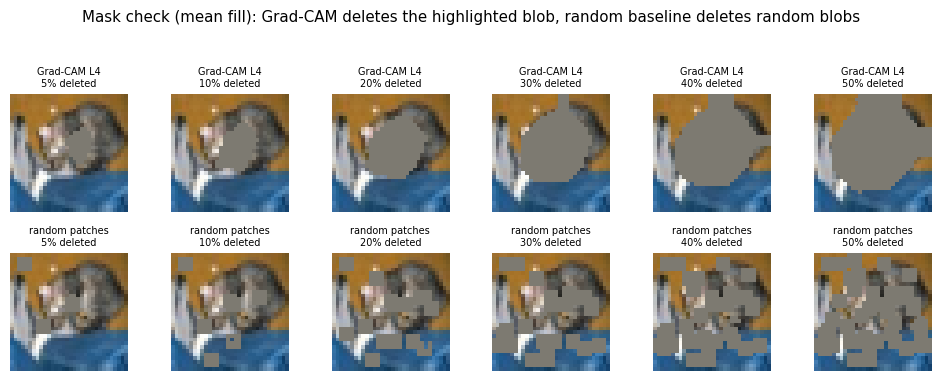

saved figure -> F11c_mask_examples


In [ ]:
# 7.1  Deletion machinery
KS = np.array(CFG["ks"]); MODES = CFG["mask_modes"]; NPIX = 32 * 32; R = CFG["n_random_draws"]
N_K = torch.tensor(np.round(KS[1:] * NPIX).astype(int), device=DEVICE)       # pixels deleted at each k > 0
DEL_METHODS = METHODS_X + [f"rand{d}" for d in range(R)]
MEAN_T = torch.tensor(MEAN, device=DEVICE).view(1, 3, 1, 1)

def patch_matrix(H=32, W=32, p=CFG["patch_size"]):
    rows = []
    for r in range(H - p + 1):
        for c in range(W - p + 1):
            m = torch.zeros(H, W, dtype=torch.bool); m[r:r + p, c:c + p] = True; rows.append(m.flatten())
    return torch.stack(rows).to(DEVICE)          # (number of positions, 1024)
P_PATCH = patch_matrix()

def masks_from_scores(score):
    """score (B,1024), higher = deleted earlier  ->  nested boolean masks (B, K-1, 1024)."""
    order = torch.argsort(score, dim=1, descending=True)
    rank = torch.argsort(order, dim=1)            # position of every pixel in the deletion order
    return rank[:, None, :] < N_K[None, :, None]

def heatmap_scores(maps, gen):
    mx = maps.amax(1, keepdim=True)
    norm = torch.where(mx > 0, maps / mx.clamp_min(1e-12), torch.zeros_like(maps))
    return norm + 1e-6 * torch.rand(maps.shape, generator=gen, device=maps.device)   # random tie-break

def random_patch_scores(B, gen):
    pos = torch.randint(0, P_PATCH.shape[0], (B, CFG["n_patches"]), generator=gen, device=DEVICE)
    cov = P_PATCH[pos]                                            # (B, n_patches, 1024)
    covered = cov.any(1)
    first = cov.float().argmax(1)                                 # index of the first patch covering each pixel
    first = torch.where(covered, first, torch.full_like(first, CFG["n_patches"]))
    return -first.float() + 0.5 * torch.rand((B, NPIX), generator=gen, device=DEVICE)

def fill_for(x, mode):
    if mode == "black": return torch.zeros_like(x)
    if mode == "mean": return MEAN_T.expand_as(x)
    if mode == "blur": return TF.gaussian_blur(x, kernel_size=[CFG["blur_kernel"]] * 2, sigma=[CFG["blur_sigma"]] * 2)
    raise ValueError(mode)

@torch.no_grad()
def deletion_probs(model, x, cls, masks, fill):
    B, K, _ = masks.shape
    m = masks.view(B, K, 1, 32, 32).float()
    xm = x[:, None] * (1 - m) + fill[:, None] * m                 # (B, K, 3, 32, 32)
    with torch.autocast("cuda", dtype=torch.float16, enabled=AMP):
        out = model(xm.view(B * K, 3, 32, 32))
    p = F.softmax(out.float(), 1).view(B, K, -1)
    return p.gather(2, cls.view(B, 1, 1).expand(B, K, 1))[..., 0]

# quick visual check of the masks for one image
i0 = 0; x0 = X_TEST[i0:i0 + 1].to(DEVICE); g0 = torch.Generator(device=DEVICE).manual_seed(0)
mk_gc = masks_from_scores(heatmap_scores(torch.from_numpy(EXPL["L4"][i0].reshape(1, -1)).to(DEVICE), g0))
mk_rd = masks_from_scores(random_patch_scores(1, g0))
fig, axes = plt.subplots(2, 6, figsize=(10, 3.6))
for c, kk in enumerate([0, 1, 3, 5, 7, 9]):
    for r_, (mk, nm) in enumerate([(mk_gc, "Grad-CAM L4"), (mk_rd, "random patches")]):
        img = fill_for(x0, "mean") * mk[0, kk].view(1, 1, 32, 32) + x0 * (~mk[0, kk]).view(1, 1, 32, 32)
        axes[r_, c].imshow(img[0].permute(1, 2, 0).cpu().numpy()); axes[r_, c].axis("off")
        axes[r_, c].set_title(f"{nm}\n{KS[kk+1]*100:.0f}% deleted", fontsize=7)
fig.suptitle("Mask check (mean fill): Grad-CAM deletes the highlighted blob, random baseline deletes random blobs")
plt.tight_layout(); savefig(fig, "F11c_mask_examples")

In [ ]:
# 7.2  Run the deletion experiment (chunked, resumable)
p0_check = []
t_start = time.time()
CH, BS = CFG["deletion_chunk"], CFG["deletion_batch"]
for ci, start in enumerate(range(0, N, CH)):
    end = min(N, start + CH); fpath = DEL_DIR / f"chunk_{ci:03d}.npy"
    if fpath.exists(): continue
    res = np.zeros((end - start, len(DEL_METHODS), len(MODES), len(KS)), np.float32)
    for b0 in range(start, end, BS):
        b1 = min(end, b0 + BS); B = b1 - b0
        x = X_TEST[b0:b1].to(DEVICE); cls = PRED_T[b0:b1].to(DEVICE)
        gen = torch.Generator(device=DEVICE).manual_seed(CFG["seed"] * 7919 + b0)
        mask_list = [masks_from_scores(heatmap_scores(torch.from_numpy(EXPL[k][b0:b1].reshape(B, -1)).to(DEVICE), gen))
                     for k in METHODS_X]
        mask_list += [masks_from_scores(random_patch_scores(B, gen)) for _ in range(R)]
        with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16, enabled=AMP):
            p0 = F.softmax(model(x).float(), 1).gather(1, cls.view(-1, 1))[:, 0]
        p0_check.append((p0.cpu().numpy() - df.conf.values[b0:b1]))
        for mo_i, mode in enumerate(MODES):
            fill = fill_for(x, mode)
            for m_i, masks in enumerate(mask_list):
                res[b0 - start:b1 - start, m_i, mo_i, 0] = p0.cpu().numpy()
                res[b0 - start:b1 - start, m_i, mo_i, 1:] = deletion_probs(model, x, cls, masks, fill).cpu().numpy()
    np.save(fpath, res)
    print(f"chunk {ci} ({start}-{end}) done | elapsed {(time.time()-t_start)/60:.1f} min")

DEL = np.concatenate([np.load(DEL_DIR / f"chunk_{ci:03d}.npy") for ci in range(len(range(0, N, CH)))])
assert DEL.shape[0] == N, DEL.shape
if p0_check:
    print("max |p0 (fp16) − confidence (fp32)| =", float(np.abs(np.concatenate(p0_check)).max()))
print("deletion array:", DEL.shape, "(images, methods, mask modes, k levels)")

chunk 0 (0-1000) done | elapsed 0.4 min
chunk 1 (1000-2000) done | elapsed 0.9 min
chunk 2 (2000-3000) done | elapsed 1.3 min
chunk 3 (3000-4000) done | elapsed 1.7 min
chunk 4 (4000-5000) done | elapsed 2.1 min
chunk 5 (5000-6000) done | elapsed 2.6 min
chunk 6 (6000-7000) done | elapsed 3.0 min
chunk 7 (7000-8000) done | elapsed 3.4 min
chunk 8 (8000-9000) done | elapsed 3.8 min
chunk 9 (9000-10000) done | elapsed 4.3 min
max |p0 (fp16) − confidence (fp32)| = 0.007446587085723877
deletion array: (10000, 9, 3, 11) (images, methods, mask modes, k levels)


In [ ]:
# 7.3  AUCs, drops, statistics (T4)
_trapz = getattr(np, "trapezoid", None) or np.trapz
AUC_ALL = _trapz(DEL, x=KS, axis=-1) / (KS[-1] - KS[0])              # (N, methods, modes)
CURVE = {k: DEL[:, j] for j, k in enumerate(METHODS_X)}               # each (N, modes, K)
CURVE["rand"] = DEL[:, len(METHODS_X):].mean(1)
AUC = {k: AUC_ALL[:, j] for j, k in enumerate(METHODS_X)}
AUC["rand"] = AUC_ALL[:, len(METHODS_X):].mean(1)
P0 = DEL[:, 0, 0, 0]
ALLM = METHODS_X + ["rand"]
i10, i20 = int(np.argmin(np.abs(KS - 0.10))), int(np.argmin(np.abs(KS - 0.20)))

summ = []
for mo_i, mode in enumerate(MODES):
    for k in ALLM:
        m, lo, hi = mean_ci(AUC[k][:, mo_i])
        summ.append({"Mask": mode, "Method": METH_NAME[k], "AUC mean [95% CI]": fmt_ci(m, lo, hi),
                     "Mean drop @10%": round(float(np.mean(P0 - CURVE[k][:, mo_i, i10])), 3),
                     "Mean drop @20%": round(float(np.mean(P0 - CURVE[k][:, mo_i, i20])), 3), "auc_mean": m})
T4a = pd.DataFrame(summ); save_table(T4a.drop(columns="auc_mean"), "T4a_deletion_auc")

PAIRS = [("L2", "rand"), ("L3", "rand"), ("L4", "rand"), ("sal", "rand"), ("L2", "sal"), ("L3", "sal"), ("L4", "sal")]
tests = []
for mo_i, mode in enumerate(MODES):
    for a, b in PAIRS:
        r, p = rb_paired(AUC[b][:, mo_i], AUC[a][:, mo_i])               # r > 0  <=>  method a has LOWER AUC (better)
        tests.append(dict(mode=mode, method=a, other=b, r=r, p=p,
                          win_rate=float(np.mean(AUC[a][:, mo_i] < AUC[b][:, mo_i])),
                          mean_auc_diff=float(np.mean(AUC[b][:, mo_i] - AUC[a][:, mo_i]))))
T4_raw = pd.DataFrame(tests); T4_raw["p_holm"] = holm(T4_raw.p)
T4_raw["verdict"] = [verdict(r, p, +1) for r, p in zip(T4_raw.r, T4_raw.p_holm)]
save_table(T4_raw, "T4_raw_tests", show=False)
T4b = pd.DataFrame({"Mask": T4_raw["mode"], "Comparison": [f"{METH_NAME[a]}  vs  {METH_NAME[b]}" for a, b in zip(T4_raw.method, T4_raw.other)],
                    "Mean AUC difference (other − method)": T4_raw.mean_auc_diff.round(4), "r": T4_raw.r.round(3),
                    "Win rate": (100 * T4_raw.win_rate).round(1).astype(str) + "%", "p (Holm)": T4_raw.p_holm.map(lambda v: f"{v:.2e}"),
                    "Method better?": T4_raw.verdict})
save_table(T4b, "T4b_deletion_tests")

rand_sd = AUC_ALL[:, len(METHODS_X):].std(1)                           # spread over the 5 random draws
RESULTS["deletion_random_draw_sd_median"] = {m: float(np.median(rand_sd[:, i])) for i, m in enumerate(MODES)}
RESULTS["RQ3"] = {f"{r.method}_vs_{r.other}_{r.mode}": dict(r=r.r, p_holm=r.p_holm, win_rate=r.win_rate) for r in T4_raw.itertuples()}
RESULTS["RQ3_auc_mean"] = {f"{r['Method']}|{r['Mask']}": r["auc_mean"] for r in summ}
save_results()

,Mask,Method,AUC mean [95% CI],Mean drop @10%,Mean drop @20%
0,black,Grad-CAM layer2 (16×16),"0.491 [0.484, 0.497]",0.338,0.480
1,black,Grad-CAM layer3 (8×8),"0.437 [0.432, 0.443]",0.321,0.515
2,black,Grad-CAM layer4 (4×4),"0.477 [0.472, 0.483]",0.277,0.476
3,black,Vanilla saliency,"0.351 [0.346, 0.357]",0.495,0.612
4,black,Random patches,"0.480 [0.474, 0.485]",0.256,0.480
5,mean,Grad-CAM layer2 (16×16),"0.600 [0.594, 0.606]",0.184,0.317
6,mean,Grad-CAM layer3 (8×8),"0.476 [0.470, 0.481]",0.243,0.452
7,mean,Grad-CAM layer4 (4×4),"0.467 [0.462, 0.472]",0.282,0.495
8,mean,Vanilla saliency,"0.487 [0.481, 0.493]",0.284,0.446
9,mean,Random patches,"0.550 [0.545, 0.555]",0.160,0.351


saved table -> T4a_deletion_auc
saved table -> T4_raw_tests


,Mask,Comparison,Mean AUC difference (other − method),r,Win rate,p (Holm),Method better?
0,black,Grad-CAM layer2 (16×16) vs Random patches,-0.0110,-0.038,51.1%,2.01e-03,✗ opposite direction
1,black,Grad-CAM layer3 (8×8) vs Random patches,0.0423,0.151,55.9%,3.57e-38,✓ supported
2,black,Grad-CAM layer4 (4×4) vs Random patches,0.0024,0.049,53.9%,7.34e-05,✓ supported
3,black,Vanilla saliency vs Random patches,0.1282,0.487,71.0%,0.00e+00,✓ supported
4,black,Grad-CAM layer2 (16×16) vs Vanilla saliency,-0.1392,-0.533,29.0%,0.00e+00,✗ opposite direction
5,black,Grad-CAM layer3 (8×8) vs Vanilla saliency,-0.0859,-0.360,35.8%,1.77e-212,✗ opposite direction
6,black,Grad-CAM layer4 (4×4) vs Vanilla saliency,-0.1259,-0.457,30.4%,0.00e+00,✗ opposite direction
7,mean,Grad-CAM layer2 (16×16) vs Random patches,-0.0509,-0.231,41.1%,4.41e-88,✗ opposite direction
8,mean,Grad-CAM layer3 (8×8) vs Random patches,0.0740,0.328,63.0%,4.99e-176,✓ supported
9,mean,Grad-CAM layer4 (4×4) vs Random patches,0.0827,0.333,64.1%,3.13e-182,✓ supported


saved table -> T4b_deletion_tests


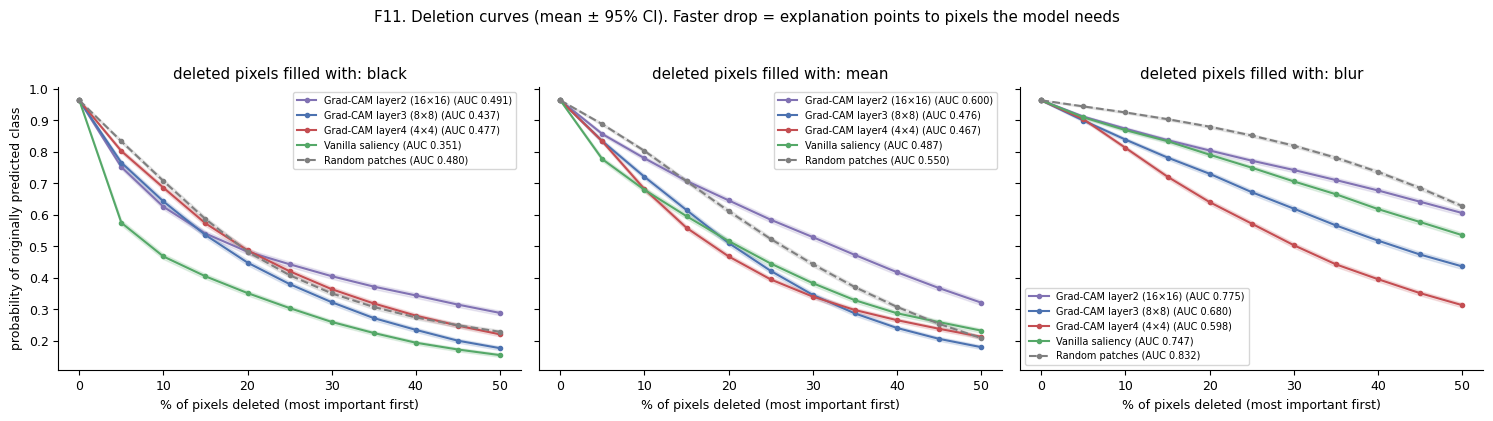

saved figure -> F11_deletion_curves


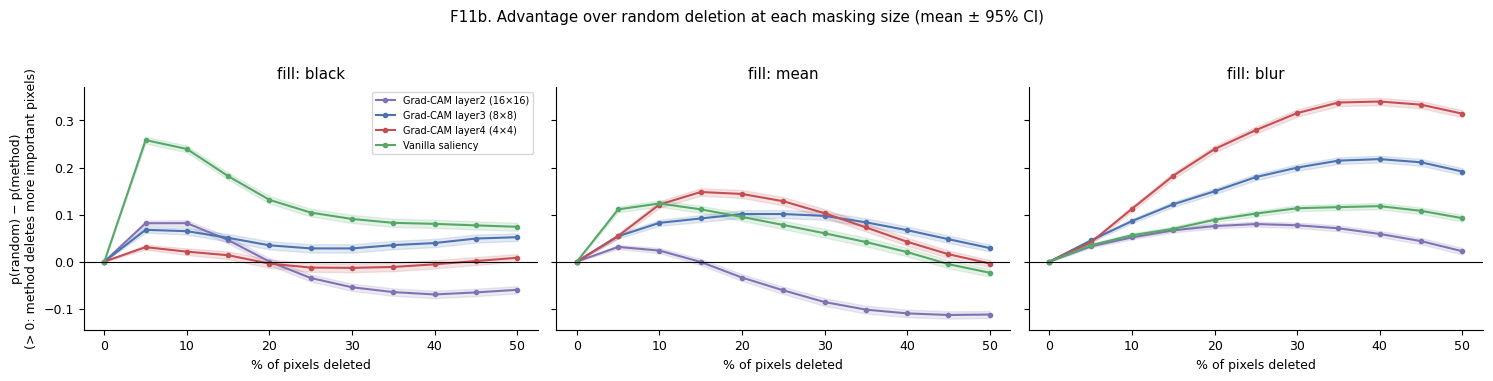

saved figure -> F11b_advantage_vs_k


In [ ]:
# 7.4  F11 – deletion curves ; F11b – difference to random vs k (mask-size sensitivity)
COLORS = {"L2": "#8172B3", "L3": "#4C72B0", "L4": "#C44E52", "sal": "#55A868", "rand": "#7F7F7F"}
fig, axes = plt.subplots(1, len(MODES), figsize=(15, 4), sharey=True)
for mo_i, (ax, mode) in enumerate(zip(axes, MODES)):
    for k in ALLM:
        c = CURVE[k][:, mo_i]; m = c.mean(0); se = c.std(0, ddof=1) / np.sqrt(len(c))
        ax.plot(KS * 100, m, marker="o", ms=3, c=COLORS[k], ls="--" if k == "rand" else "-",
                label=f"{METH_NAME[k]} (AUC {AUC[k][:, mo_i].mean():.3f})")
        ax.fill_between(KS * 100, m - 1.96 * se, m + 1.96 * se, color=COLORS[k], alpha=0.15)
    ax.set_title(f"deleted pixels filled with: {mode}"); ax.set_xlabel("% of pixels deleted (most important first)")
    ax.legend(fontsize=7)
axes[0].set_ylabel("probability of originally predicted class")
fig.suptitle("F11. Deletion curves (mean ± 95% CI). Faster drop = explanation points to pixels the model needs")
plt.tight_layout(); savefig(fig, "F11_deletion_curves")

fig, axes = plt.subplots(1, len(MODES), figsize=(15, 3.6), sharey=True)
H3_K = {}
for mo_i, (ax, mode) in enumerate(zip(axes, MODES)):
    for k in METHODS_X:
        d = CURVE["rand"][:, mo_i] - CURVE[k][:, mo_i]; m = d.mean(0); se = d.std(0, ddof=1) / np.sqrt(len(d))
        ax.plot(KS * 100, m, "-o", ms=3, c=COLORS[k], label=METH_NAME[k])
        ax.fill_between(KS * 100, m - 1.96 * se, m + 1.96 * se, color=COLORS[k], alpha=0.15)
        H3_K[(k, mode)] = [int(round(100 * KS[j])) for j in range(1, len(KS)) if m[j] - 1.96 * se[j] > 0]
    ax.axhline(0, c="k", lw=0.8); ax.set_title(f"fill: {mode}"); ax.set_xlabel("% of pixels deleted")
axes[0].set_ylabel("p(random) − p(method)\n(> 0: method deletes more important pixels)"); axes[0].legend(fontsize=7)
fig.suptitle("F11b. Advantage over random deletion at each masking size (mean ± 95% CI)")
plt.tight_layout(); savefig(fig, "F11b_advantage_vs_k")

**Interpretation guide (Step 7):**

| What you see | Meaning |
|---|---|
| Grad-CAM curve clearly below random for all 3 fills | H3 strongly supported **and** robust to the out-of-distribution masking problem |
| Below random for black/mean but not blur | part of the apparent faithfulness is a **masking artefact** (important finding) |
| L4 beats L2, or vice versa | which layer gives the most *faithful* map; compare with which looks most *plausible* in F4. If they differ, plausibility ≠ faithfulness |
| Saliency beats Grad-CAM | pixel-level attributions find important pixels better at this resolution |
| Curves separate only at k ≥ 20 % (F11b) | Grad-CAM finds the right *area* but not the most important *pixels*, consistent with its coarse resolution |
| High win rate but small AUC difference | consistently better, but only slightly |

**Checks:** at k = 0 all methods have the same value; the random curve should fall slowly. If a Grad-CAM curve lies *above* random everywhere, check the ranking direction before believing it.

---
# STEP 8 — RQ4: is Grad-CAM less faithful on mistakes?
**Why:** connects both halves of the project. Grad-CAM may be faithful *on average* but **unfaithful exactly on mistakes**, which is when a user needs it most.
**What:** per-image **advantage = AUC(random) − AUC(Grad-CAM)** (> 0: better than chance). Compare correct vs incorrect vs confident mistakes.
**Confidence confound:** a mistake starting at p = 0.4 can drop by at most 0.4; a correct image at 0.99 by 0.99. So mistakes may *look* less faithful just because they have less room to fall. Two fixes:
1. **Normalised advantage** = advantage / starting probability.
2. **Confidence matching:** each mistake is paired with a correct image from the same confidence bin (width 0.05) → paired Wilcoxon test.

H4 predicts **r < 0** (smaller advantage for mistakes). If the effect survives both fixes, it is real.

In [ ]:
# 8.1  T5 – RQ4 statistics
rng_m = np.random.default_rng(CFG["seed"] + 2)
KEPT, CTRL = matched_controls(P0, INC, COR, CFG["conf_bin_width"], rng_m)
print(f"matched pairs: {len(KEPT)} of {INC.sum()} mistakes | median conf mistakes {np.median(P0[KEPT]):.3f} "
      f"vs matched correct {np.median(P0[CTRL]):.3f}")
ADV = {(k, mo): AUC["rand"][:, i] - AUC[k][:, i] for k in METHODS_X for i, mo in enumerate(MODES)}
ADVN = {key: v / np.clip(P0, 1e-6, None) for key, v in ADV.items()}

rows = []
for k in METHODS_X:
    for mo in MODES:
        a, an = ADV[(k, mo)], ADVN[(k, mo)]
        r_raw, p_raw = rb_ind(a[INC], a[COR]); r_cm, p_cm = rb_ind(a[CM], a[COR])
        r_n, p_n = rb_ind(an[INC], an[COR]); r_m, p_m = rb_paired(a[KEPT], a[CTRL])
        rows.append(dict(method=k, mode=mo, med_cor=np.median(a[COR]), med_inc=np.median(a[INC]),
                         med_cm=np.median(a[CM]) if CM.sum() else np.nan,
                         r_raw=r_raw, p_raw=p_raw, r_cm=r_cm, p_cm=p_cm, r_norm=r_n, p_norm=p_n, r_match=r_m, p_match=p_m))
T5_raw = pd.DataFrame(rows)
for c in ["raw", "cm", "norm", "match"]:
    T5_raw[f"p_{c}_holm"] = holm(T5_raw[f"p_{c}"])
T5_raw["H4_raw"] = [verdict(r, p, -1) for r, p in zip(T5_raw.r_raw, T5_raw.p_raw_holm)]
T5_raw["H4_matched"] = [verdict(r, p, -1) for r, p in zip(T5_raw.r_match, T5_raw.p_match_holm)]
save_table(T5_raw, "T5_raw", show=False)
T5 = pd.DataFrame({
    "Method": T5_raw.method.map(METH_NAME), "Mask": T5_raw["mode"],
    "Median adv. correct": T5_raw.med_cor.round(4), "Median adv. incorrect": T5_raw.med_inc.round(4),
    "Median adv. conf. mistake": T5_raw.med_cm.round(4),
    "r raw (inc vs cor)": [f"{r:+.3f} {stars(p)}" for r, p in zip(T5_raw.r_raw, T5_raw.p_raw_holm)],
    "r conf.mistake vs cor": [f"{r:+.3f} {stars(p)}" for r, p in zip(T5_raw.r_cm, T5_raw.p_cm_holm)],
    "r normalised": [f"{r:+.3f} {stars(p)}" for r, p in zip(T5_raw.r_norm, T5_raw.p_norm_holm)],
    "r confidence-matched": [f"{r:+.3f} {stars(p)}" for r, p in zip(T5_raw.r_match, T5_raw.p_match_holm)],
    "H4 (raw)": T5_raw.H4_raw, "H4 (matched)": T5_raw.H4_matched})
save_table(T5, "T5_rq4")
RESULTS["RQ4"] = {f"{r.method}_{r.mode}": dict(r_raw=r.r_raw, p_raw_holm=r.p_raw_holm, r_matched=r.r_match,
                  p_matched_holm=r.p_match_holm, H4_raw=r.H4_raw, H4_matched=r.H4_matched) for r in T5_raw.itertuples()}
RESULTS["RQ4_matched_pairs"] = int(len(KEPT))
save_results()

matched pairs: 685 of 686 mistakes | median conf mistakes 0.804 vs matched correct 0.805
saved table -> T5_raw


,Method,Mask,Median adv. correct,Median adv. incorrect,Median adv. conf. mistake,r raw (inc vs cor),r conf.mistake vs cor,r normalised,r confidence-matched,H4 (raw),H4 (matched)
0,Grad-CAM layer2 (16×16),black,0.0019,0.0131,0.0035,+0.075 **,+0.100 ns,+0.083 **,+0.044 ns,✗ opposite direction,✗ not significant
1,Grad-CAM layer2 (16×16),mean,-0.0480,0.0266,0.0337,+0.179 ***,+0.155 **,+0.170 ***,+0.114 ns,✗ opposite direction,✗ not significant
2,Grad-CAM layer2 (16×16),blur,-0.0003,0.1335,0.0705,+0.284 ***,+0.149 **,+0.321 ***,+0.111 ns,✗ opposite direction,✗ not significant
3,Grad-CAM layer3 (8×8),black,0.0329,0.0111,0.0130,-0.059 *,-0.063 ns,-0.049 ns,-0.002 ns,✓ supported,✗ not significant
4,Grad-CAM layer3 (8×8),mean,0.0852,0.0380,0.0460,-0.068 *,-0.032 ns,-0.033 ns,-0.026 ns,✓ supported,✗ not significant
5,Grad-CAM layer3 (8×8),blur,0.0844,0.1769,0.1627,+0.125 ***,+0.107 ns,+0.210 ***,+0.042 ns,✗ opposite direction,✗ not significant
6,Grad-CAM layer4 (4×4),black,0.0200,0.0091,0.0084,-0.010 ns,+0.013 ns,-0.002 ns,-0.028 ns,✗ not significant,✗ not significant
7,Grad-CAM layer4 (4×4),mean,0.1034,0.0418,0.0917,-0.100 ***,+0.032 ns,-0.067 *,-0.042 ns,✓ supported,✗ not significant
8,Grad-CAM layer4 (4×4),blur,0.2230,0.1720,0.2165,-0.134 ***,-0.036 ns,-0.024 ns,-0.054 ns,✓ supported,✗ not significant
9,Vanilla saliency,black,0.1370,0.0280,0.0619,-0.239 ***,-0.151 **,-0.204 ***,-0.104 ns,✓ supported,✗ not significant


saved table -> T5_rq4


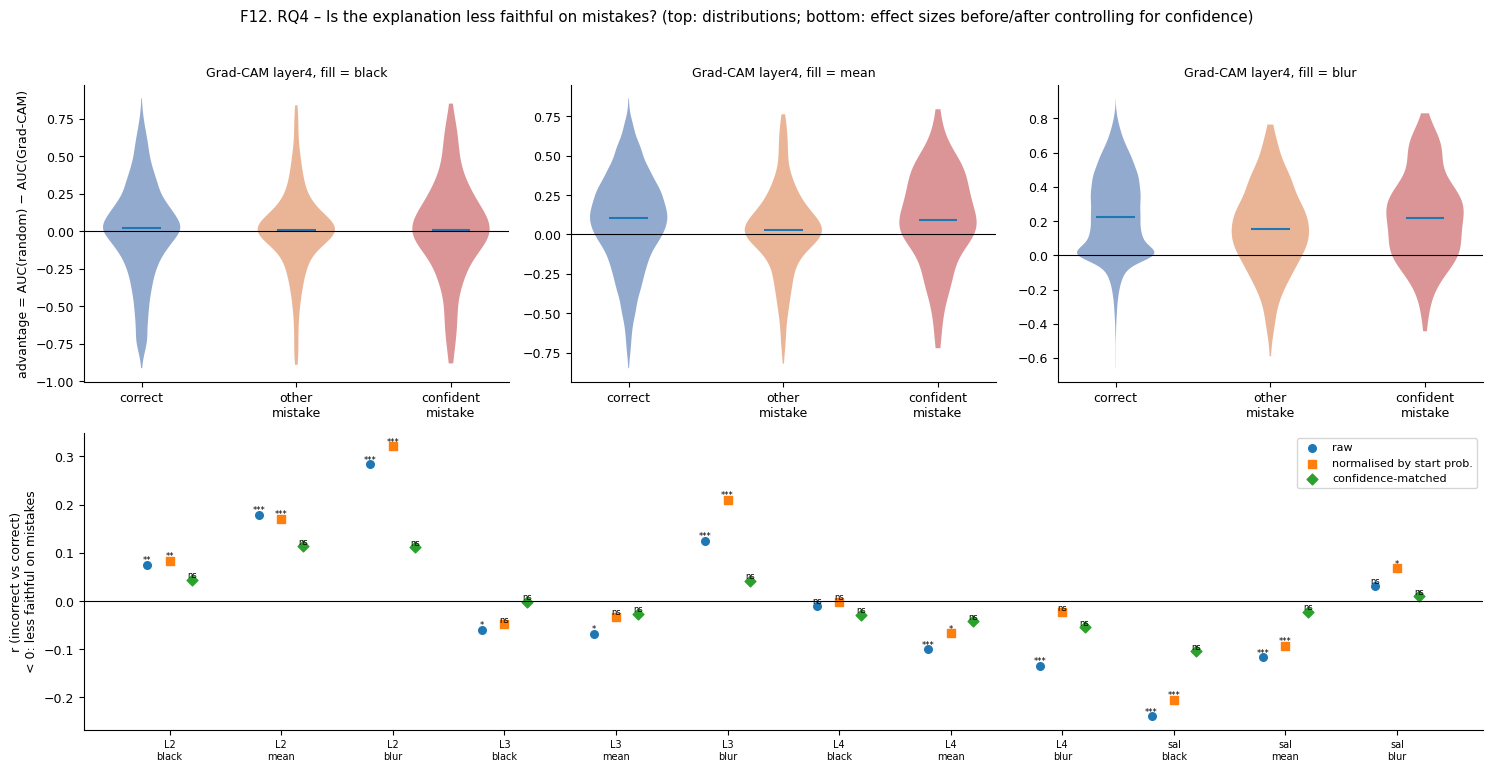

saved figure -> F12_rq4_faithfulness_on_mistakes


In [ ]:
# 8.2  F12 – advantage by group, and effect sizes before/after controlling for confidence
fig = plt.figure(figsize=(15, 7.5)); gs = fig.add_gridspec(2, len(MODES))
for mo_i, mo in enumerate(MODES):
    ax = fig.add_subplot(gs[0, mo_i]); a = ADV[("L4", mo)]
    data = [a[COR], a[(df.group == "other mistake").values], a[CM]]
    ok = [i for i, d in enumerate(data) if len(d) > 1]
    parts = ax.violinplot([data[i] for i in ok], positions=[i + 1 for i in ok], showmedians=True, showextrema=False)
    for pc, i in zip(parts["bodies"], ok): pc.set_facecolor(GC[i]); pc.set_alpha(0.6)
    ax.axhline(0, c="k", lw=0.8); ax.set_xticks([1, 2, 3]); ax.set_xticklabels(["correct", "other\nmistake", "confident\nmistake"])
    ax.set_title(f"Grad-CAM layer4, fill = {mo}", fontsize=9)
    if mo_i == 0: ax.set_ylabel("advantage = AUC(random) − AUC(Grad-CAM)")
ax = fig.add_subplot(gs[1, :])
labels_x = [f"{k}\n{mo}" for k in METHODS_X for mo in MODES]; xpos = np.arange(len(labels_x))
for off, (col, pcol, lab, mk) in zip([-0.2, 0, 0.2], [("r_raw", "p_raw_holm", "raw", "o"), ("r_norm", "p_norm_holm", "normalised by start prob.", "s"),
                                                       ("r_match", "p_match_holm", "confidence-matched", "D")]):
    vals = T5_raw[col].values; ps = T5_raw[pcol].values
    ax.scatter(xpos + off, vals, marker=mk, label=lab, s=30)
    for x_, v_, p_ in zip(xpos + off, vals, ps):
        ax.text(x_, v_, stars(p_), fontsize=6, ha="center", va="bottom")
ax.axhline(0, c="k", lw=0.8); ax.set_xticks(xpos); ax.set_xticklabels(labels_x, fontsize=7)
ax.set_ylabel("r (incorrect vs correct)\n< 0: less faithful on mistakes"); ax.legend(fontsize=8)
fig.suptitle("F12. RQ4 – Is the explanation less faithful on mistakes? (top: distributions; bottom: effect sizes before/after controlling for confidence)")
plt.tight_layout(); savefig(fig, "F12_rq4_faithfulness_on_mistakes")

**Interpretation guide (Step 8):**

| What you see | Meaning |
|---|---|
| r < 0 raw **and** after matching/normalising | H4 supported: Grad-CAM is less faithful on mistakes, a serious practical warning |
| r < 0 raw, but ≈ 0 after matching | the effect was **only the confidence difference**; you showed why a naive analysis misleads (still a strong result) |
| r ≈ 0 everywhere | Grad-CAM is equally faithful on right and wrong predictions: it honestly shows what the model used, even when that is wrong |
| confident mistakes ≈ correct | model was "confidently wrong for a clear reason" → combine with F9/F14 to show the reason |

---
# STEP 9 — Sensitivity analysis (robustness summary)
**Why:** a conclusion that holds only for one setting is not trustworthy. This step shows which findings are **robust** and which are **fragile**.

| Factor | Settings | Hypotheses |
|---|---|---|
| Grad-CAM layer | L2 / L3 / L4 | H1–H4 |
| Concentration metric | area-50 / entropy | H1 |
| Confident-mistake definition | top 25 % / top 10 % / conf ≥ 0.9 | H2 |
| Deletion fill | black / mean / blur | H3, H4 |
| Masking size | 5 … 50 % | H3 (from F11b) |
| Confidence control | raw / normalised / matched | H4 |

For **H2** there is no ✓/✗: the table reports the AUROC and the confidence AUROC side by side, and you judge whether the explanation is a "reliable" detector.

,Hypothesis,Setting,Effect,p (Holm),Result
0,H1,"L2, area50",r = -0.292,6.91e-37,✗ opposite direction
1,H1,"L2, entropy",r = -0.297,4.38e-38,✗ opposite direction
2,H1,"L3, area50",r = +0.405,1.30e-68,✓ supported
3,H1,"L3, entropy",r = +0.407,2.42e-69,✓ supported
4,H1,"L4, area50",r = -0.393,9.06e-66,✗ opposite direction
5,H1,"L4, entropy",r = -0.395,4.49e-66,✗ opposite direction
6,H2,"L2, CM = top 25% of errors (n=172)","AUROC = 0.428 [0.389, 0.468] | confidence AURO...",,interpret (0.5 = chance)
7,H2,"L3, CM = top 25% of errors (n=172)","AUROC = 0.671 [0.633, 0.709] | confidence AURO...",,interpret (0.5 = chance)
8,H2,"L4, CM = top 25% of errors (n=172)","AUROC = 0.390 [0.346, 0.431] | confidence AURO...",,interpret (0.5 = chance)
9,H2,"L2, CM = top 10% of errors (n=69)","AUROC = 0.419 [0.357, 0.481] | confidence AURO...",,interpret (0.5 = chance)


saved table -> T6_robustness_summary


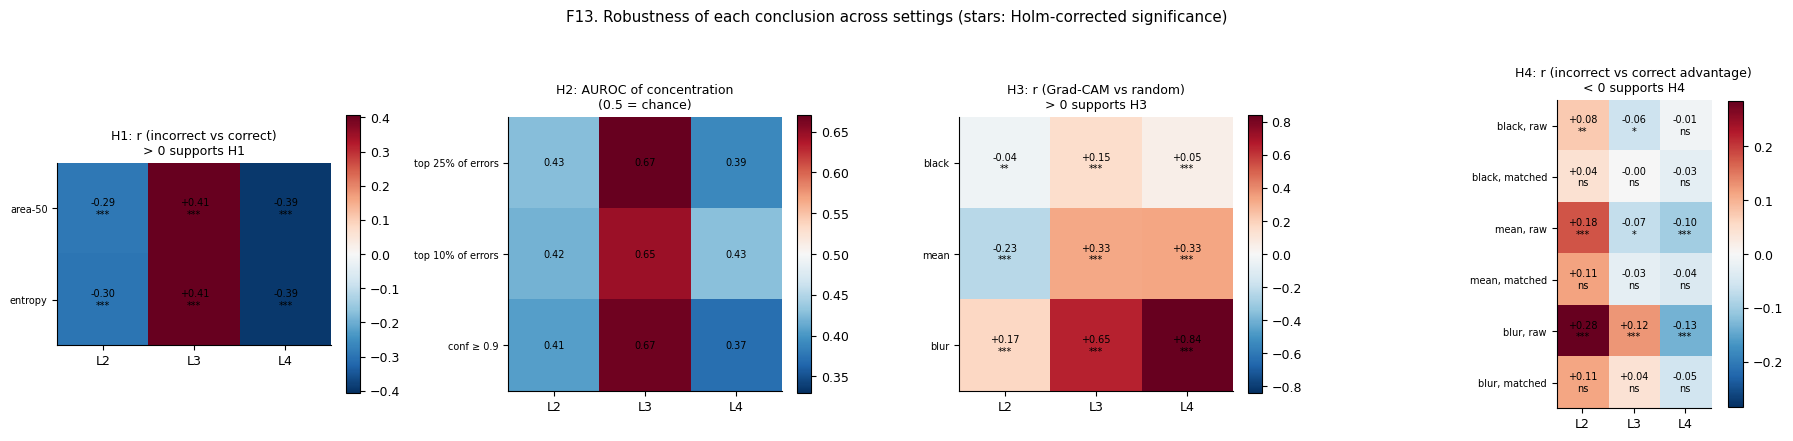

saved figure -> F13_robustness_heatmaps


In [ ]:
# 9.1  T6 – robustness table ; F13 – robustness heatmaps
t6 = []
for r in T2_raw[T2_raw.method.isin(["L2", "L3", "L4"])].itertuples():
    t6.append(dict(Hypothesis="H1", Setting=f"{r.method}, {r.metric}", Effect=f"r = {r.r:+.3f}", **{"p (Holm)": r.p_holm}, Result=r.H1))
CM_DEFS = [("top 25% of errors", CM), ("top 10% of errors", df.cm_top10.values), ("conf ≥ 0.9", df.cm_abs.values)]
H2_GRID = np.full((len(CM_DEFS), 3), np.nan)
for i, (nm, mask) in enumerate(CM_DEFS):
    c_au = auc_groups(-df.conf.values, mask, COR) if mask.sum() >= 5 else (np.nan,) * 3
    for j, k in enumerate(["L2", "L3", "L4"]):
        if mask.sum() < 5:
            t6.append(dict(Hypothesis="H2", Setting=f"{k}, CM = {nm}", Effect="too few cases", **{"p (Holm)": np.nan}, Result="–")); continue
        a = auc_groups(df[f"area50_{k}"].values, mask, COR); H2_GRID[i, j] = a[0]
        t6.append(dict(Hypothesis="H2", Setting=f"{k}, CM = {nm} (n={mask.sum()})",
                       Effect=f"AUROC = {fmt_ci(*a)} | confidence AUROC = {c_au[0]:.3f}", **{"p (Holm)": np.nan},
                       Result="interpret (0.5 = chance)"))
for r in T4_raw[(T4_raw.other == "rand") & T4_raw.method.isin(["L2", "L3", "L4"])].itertuples():
    t6.append(dict(Hypothesis="H3", Setting=f"{r.method}, fill = {r.mode}", Effect=f"r = {r.r:+.3f}, win rate {100*r.win_rate:.1f}%",
                   **{"p (Holm)": r.p_holm}, Result=r.verdict))
for (k, mo), ks_sig in H3_K.items():
    if k in ["L2", "L3", "L4"]:
        t6.append(dict(Hypothesis="H3 (mask size)", Setting=f"{k}, fill = {mo}",
                       Effect=f"better than random (95% CI > 0) at k = {ks_sig if ks_sig else 'none'} %",
                       **{"p (Holm)": np.nan}, Result=f"{len(ks_sig)}/{len(KS)-1} levels"))
for r in T5_raw[T5_raw.method.isin(["L2", "L3", "L4"])].itertuples():
    for lab, rr, pp in [("raw", r.r_raw, r.p_raw_holm), ("normalised", r.r_norm, r.p_norm_holm), ("matched", r.r_match, r.p_match_holm)]:
        t6.append(dict(Hypothesis="H4", Setting=f"{r.method}, fill = {r.mode}, {lab}", Effect=f"r = {rr:+.3f}",
                       **{"p (Holm)": pp}, Result=verdict(rr, pp, -1)))
T6 = pd.DataFrame(t6); T6["p (Holm)"] = T6["p (Holm)"].map(lambda v: "" if pd.isna(v) else f"{v:.2e}")
save_table(T6, "T6_robustness_summary")
RESULTS["robustness_counts"] = {h: s_.value_counts().to_dict() for h, s_ in T6.groupby("Hypothesis")["Result"]}
save_results()

def grid_plot(ax, M, P, rows_, cols_, title, center=0.0, fmt="{:+.2f}"):
    M = np.asarray(M, float); span = np.nanmax(np.abs(M - center)) if np.isfinite(M).any() else 1
    span = span if span > 0 else 1
    im = ax.imshow(M, cmap="RdBu_r", vmin=center - span, vmax=center + span)
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            if np.isfinite(M[i, j]):
                s = fmt.format(M[i, j]) + ("" if P is None else "\n" + stars(P[i][j]))
                ax.text(j, i, s, ha="center", va="center", fontsize=7)
    ax.set_xticks(range(len(cols_))); ax.set_xticklabels(cols_); ax.set_yticks(range(len(rows_))); ax.set_yticklabels(rows_, fontsize=7)
    ax.set_title(title, fontsize=9); plt.colorbar(im, ax=ax, fraction=0.046)

LAY = ["L2", "L3", "L4"]
fig, axes = plt.subplots(1, 4, figsize=(18, 4.2), gridspec_kw=dict(width_ratios=[1, 1, 1, 1.1]))
sel_ = lambda mt: T2_raw[(T2_raw.metric == mt)].set_index("method")
grid_plot(axes[0], [[sel_(mt).loc[k, "r"] for k in LAY] for mt in ["area50", "entropy"]],
          [[sel_(mt).loc[k, "p_holm"] for k in LAY] for mt in ["area50", "entropy"]], ["area-50", "entropy"], LAY,
          "H1: r (incorrect vs correct)\n> 0 supports H1")
grid_plot(axes[1], H2_GRID, None, [n for n, _ in CM_DEFS], LAY, "H2: AUROC of concentration\n(0.5 = chance)", center=0.5, fmt="{:.2f}")
t3r = T4_raw[T4_raw.other == "rand"].set_index(["method", "mode"])
grid_plot(axes[2], [[t3r.loc[(k, mo), "r"] for k in LAY] for mo in MODES], [[t3r.loc[(k, mo), "p_holm"] for k in LAY] for mo in MODES],
          MODES, LAY, "H3: r (Grad-CAM vs random)\n> 0 supports H3")
t5r = T5_raw.set_index(["method", "mode"]); rws = [f"{mo}, {lab}" for mo in MODES for lab in ["raw", "matched"]]
grid_plot(axes[3], [[t5r.loc[(k, mo), "r_raw" if lab == "raw" else "r_match"] for k in LAY] for mo in MODES for lab in ["raw", "matched"]],
          [[t5r.loc[(k, mo), "p_raw_holm" if lab == "raw" else "p_match_holm"] for k in LAY] for mo in MODES for lab in ["raw", "matched"]],
          rws, LAY, "H4: r (incorrect vs correct advantage)\n< 0 supports H4")
fig.suptitle("F13. Robustness of each conclusion across settings (stars: Holm-corrected significance)")
plt.tight_layout(); savefig(fig, "F13_robustness_heatmaps")

**Interpretation guide (Step 9):** a hypothesis that is ✓ in every row is a **robust** finding (state it confidently in the conclusion). One that flips with a single factor is **fragile**: name the factor and explain why (e.g. *"H3 holds for black and mean fills but weakens under blur, so part of the deletion effect reflects distribution shift"*). This table is where examiners see scientific maturity.

---
# STEP 10 — Failure-case analysis
**Why:** averages hide *why* a method fails; the course explicitly asks for unexpected results and failure cases.
**How:** examples are selected **automatically by rule** (not hand-picked):
1. **Confident mistakes with the most concentrated maps** → direct evidence for H2 (focused map, wrong answer)
2. **Grad-CAM worse than random** (largest AUC(Grad-CAM) − AUC(random), mean fill) → Grad-CAM pointed to the wrong place
3. **All-zero Grad-CAM maps** (layer4) → no explanation at all
4. **Same region, wrong class** (mistakes with highest predicted-vs-true map similarity)
5. **Grad-CAM vs saliency disagree** (lowest Spearman between the two maps)

Each row: image · Grad-CAM L4 · Grad-CAM L2 · saliency · Grad-CAM L4 for the **true** class · deletion curve.

In [ ]:
# 10.1  Select failure cases
nF = CFG["n_fail_examples"]; mo_mean = MODES.index("mean")
FAIL = {}
cand = np.where(CM & ~df.zero_L4.values)[0]
FAIL["1_confident_mistake_focused_map"] = cand[np.argsort(df.area50_L4.values[cand])][:nF]
gap = AUC["L4"][:, mo_mean] - AUC["rand"][:, mo_mean]
FAIL["2_gradcam_worse_than_random"] = np.argsort(-gap)[:nF]
zz = np.where(df.zero_L4.values)[0]
FAIL["3_all_zero_gradcam"] = np.random.default_rng(CFG["seed"]).choice(zz, size=min(nF, len(zz)), replace=False) if len(zz) else np.array([], int)
okk = np.where(~np.isnan(SIM_PT["L4"]))[0]
FAIL["4_same_region_wrong_class"] = err_idx[okk[np.argsort(-SIM_PT["L4"][okk])][:nF]]
gs_rho = rowwise_spearman(EXPL["L4"].reshape(N, -1), EXPL["sal"].reshape(N, -1))
okg = np.where(~np.isnan(gs_rho))[0]
FAIL["5_gradcam_vs_saliency_disagree"] = okg[np.argsort(gs_rho[okg])][:nF]

def describe(idx):
    sub = df.iloc[idx]
    return {"n": len(idx), "% correct": round(100 * sub.correct.mean(), 1) if len(idx) else np.nan,
            "median conf": round(sub.conf.median(), 3) if len(idx) else np.nan,
            "examples (true→pred)": "; ".join(f"{t}→{p}" for t, p in zip(sub.true_name, sub.pred_name))}
T7 = pd.DataFrame([{"Failure group": g, **describe(np.asarray(i, int))} for g, i in FAIL.items()])
save_table(T7, "T7_failure_cases")

# broader statistics for the patterns (not only the shown examples)
nz = np.where(df.zero_L4.values)[0]
if len(nz):
    print("All-zero Grad-CAM (layer4) by predicted class:\n", df.iloc[nz].pred_name.value_counts().to_string())
worst = np.argsort(-gap)[:max(50, nF)]
print("\nGrad-CAM worse than random (top 50): % mistakes =", round(100 * (~df.correct.values[worst]).mean(), 1),
      "| most frequent true classes:", df.iloc[worst].true_name.value_counts().head(3).to_dict())

,Failure group,n,% correct,median conf,examples (true→pred)
0,1_confident_mistake_focused_map,6,0.0,0.973,cat→truck; bird→horse; cat→dog; cat→horse; cat...
1,2_gradcam_worse_than_random,6,100.0,0.996,bird→bird; bird→bird; bird→bird; bird→bird; bi...
2,3_all_zero_gradcam,0,NaN,NaN,
3,4_same_region_wrong_class,6,0.0,0.784,cat→dog; airplane→bird; dog→cat; airplane→bird...
4,5_gradcam_vs_saliency_disagree,6,83.3,0.997,cat→bird; bird→bird; automobile→automobile; au...


saved table -> T7_failure_cases

Grad-CAM worse than random (top 50): % mistakes = 2.0 | most frequent true classes: {'bird': 44, 'ship': 4, 'cat': 2}


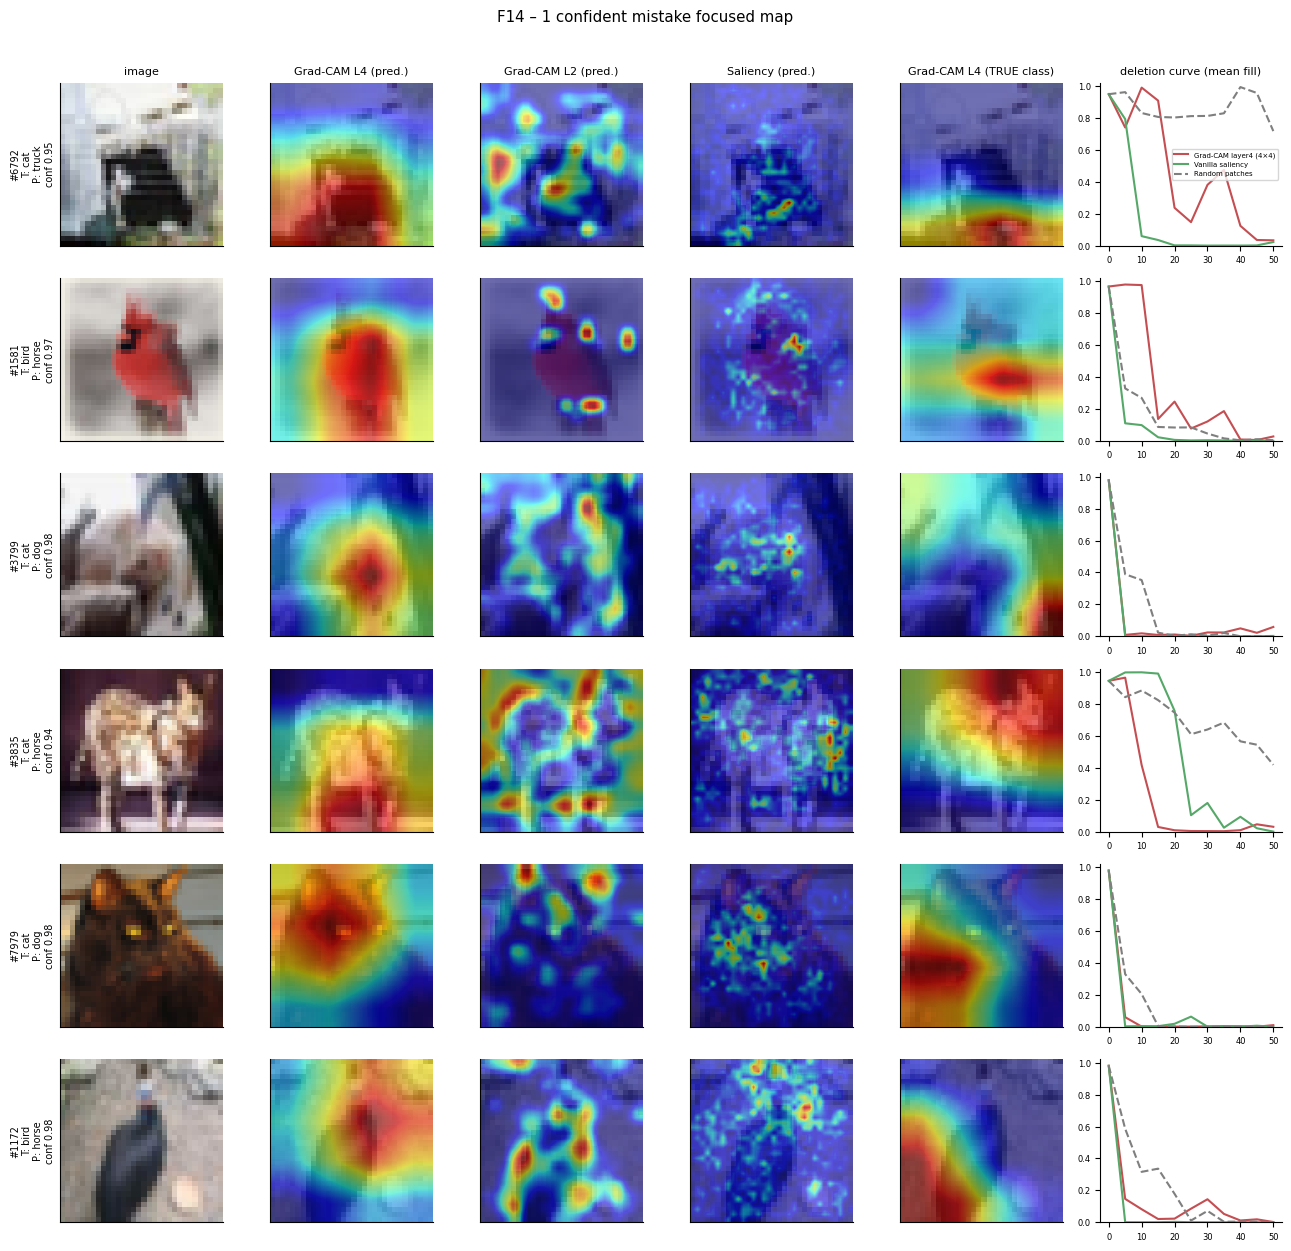

saved figure -> F14_1_confident_mistake_focused_map


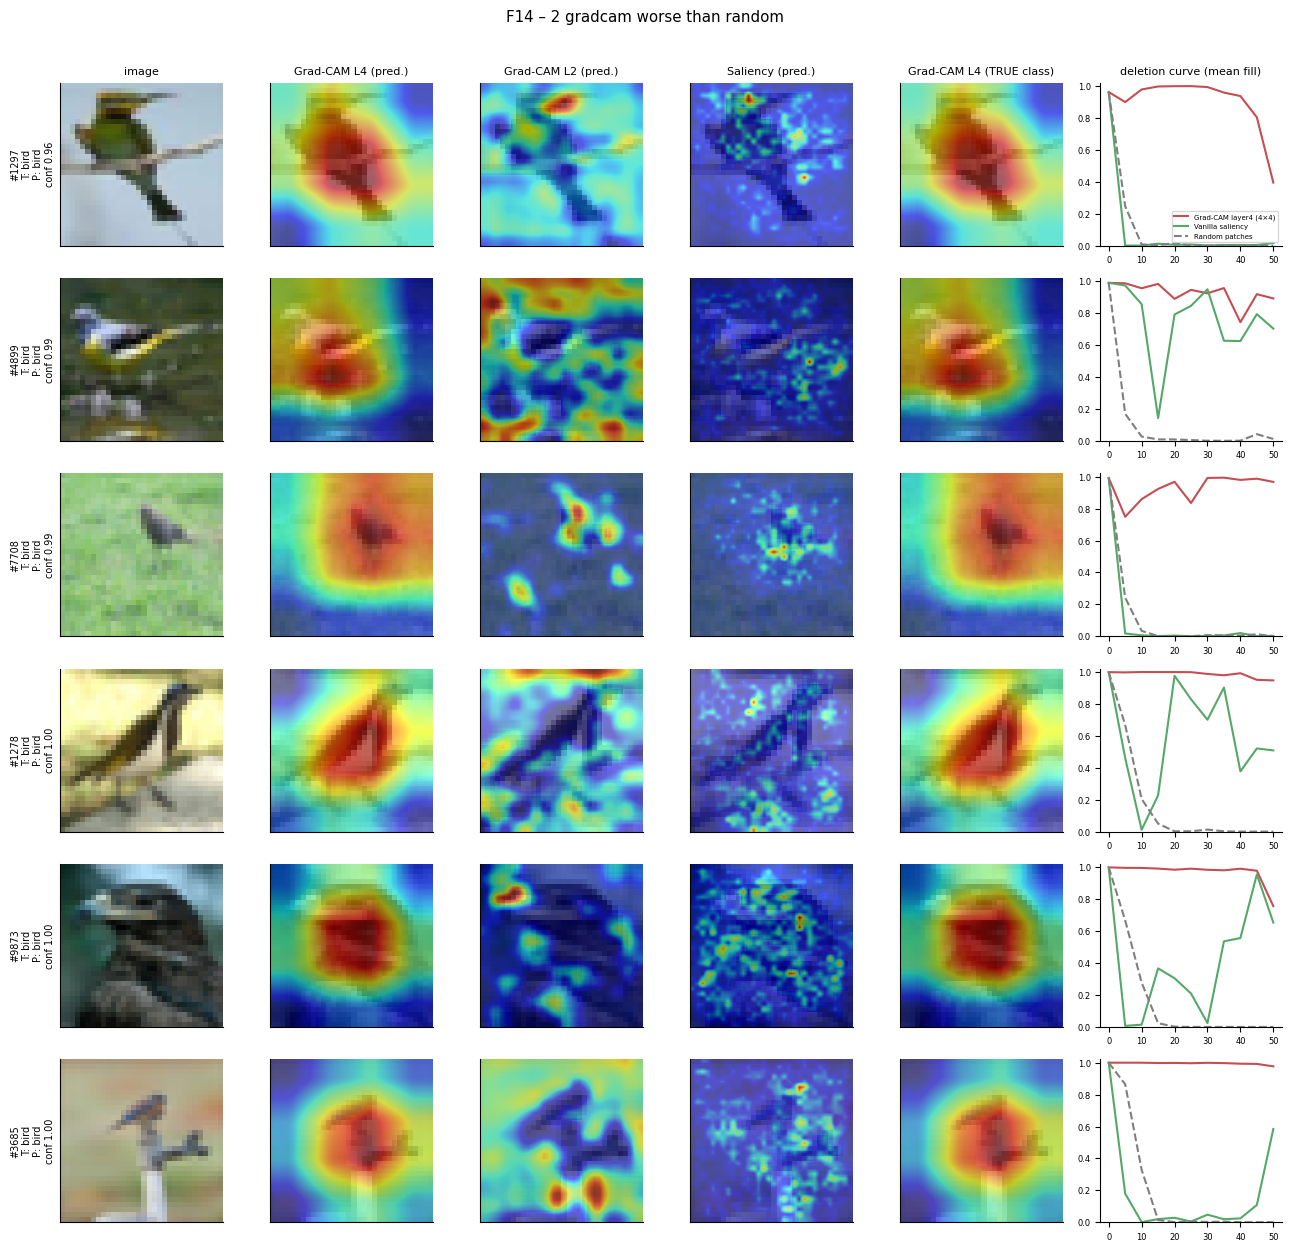

saved figure -> F14_2_gradcam_worse_than_random
no cases for F14 – 3 all zero gradcam


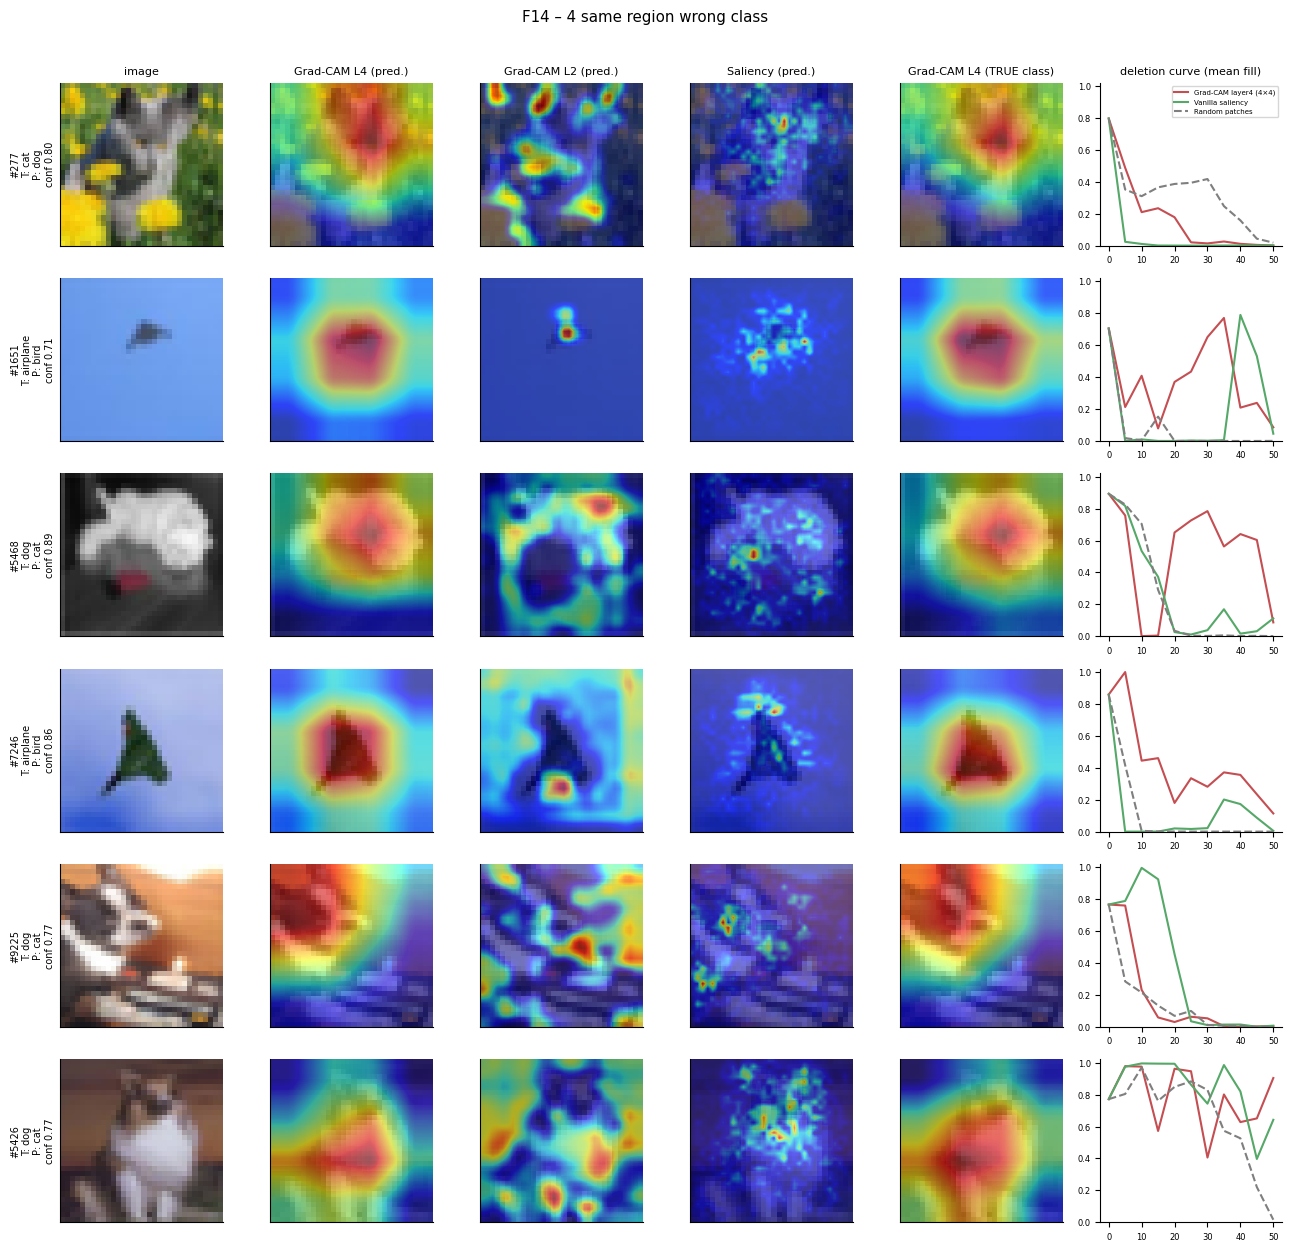

saved figure -> F14_4_same_region_wrong_class


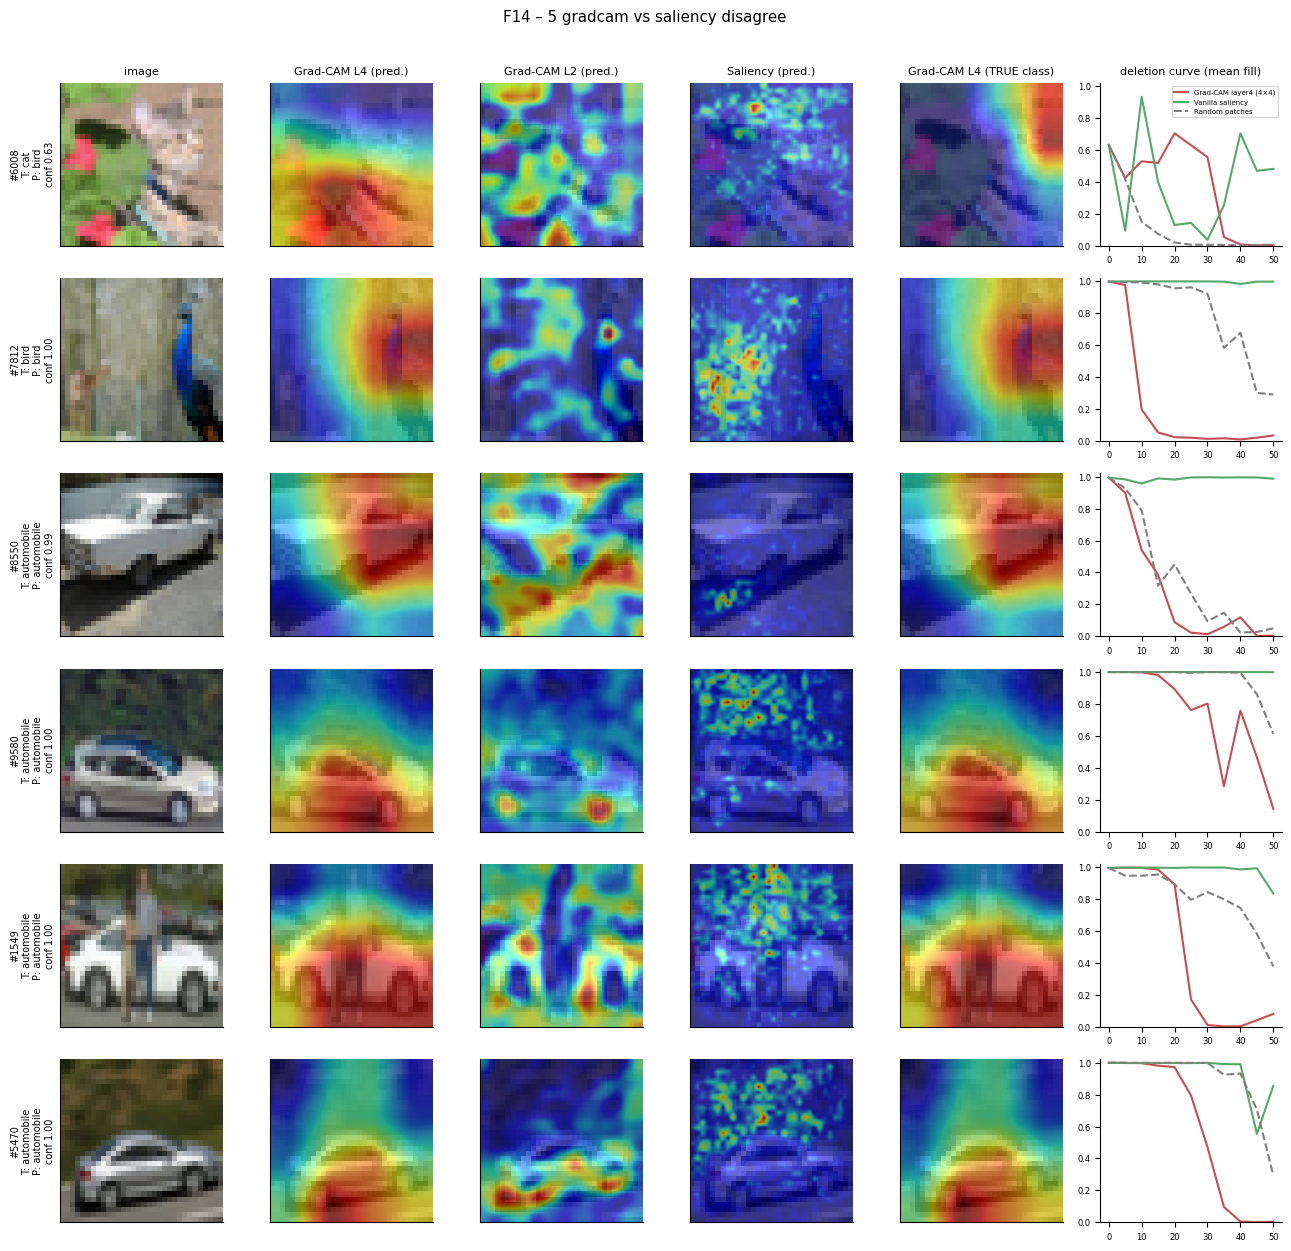

saved figure -> F14_5_gradcam_vs_saliency_disagree


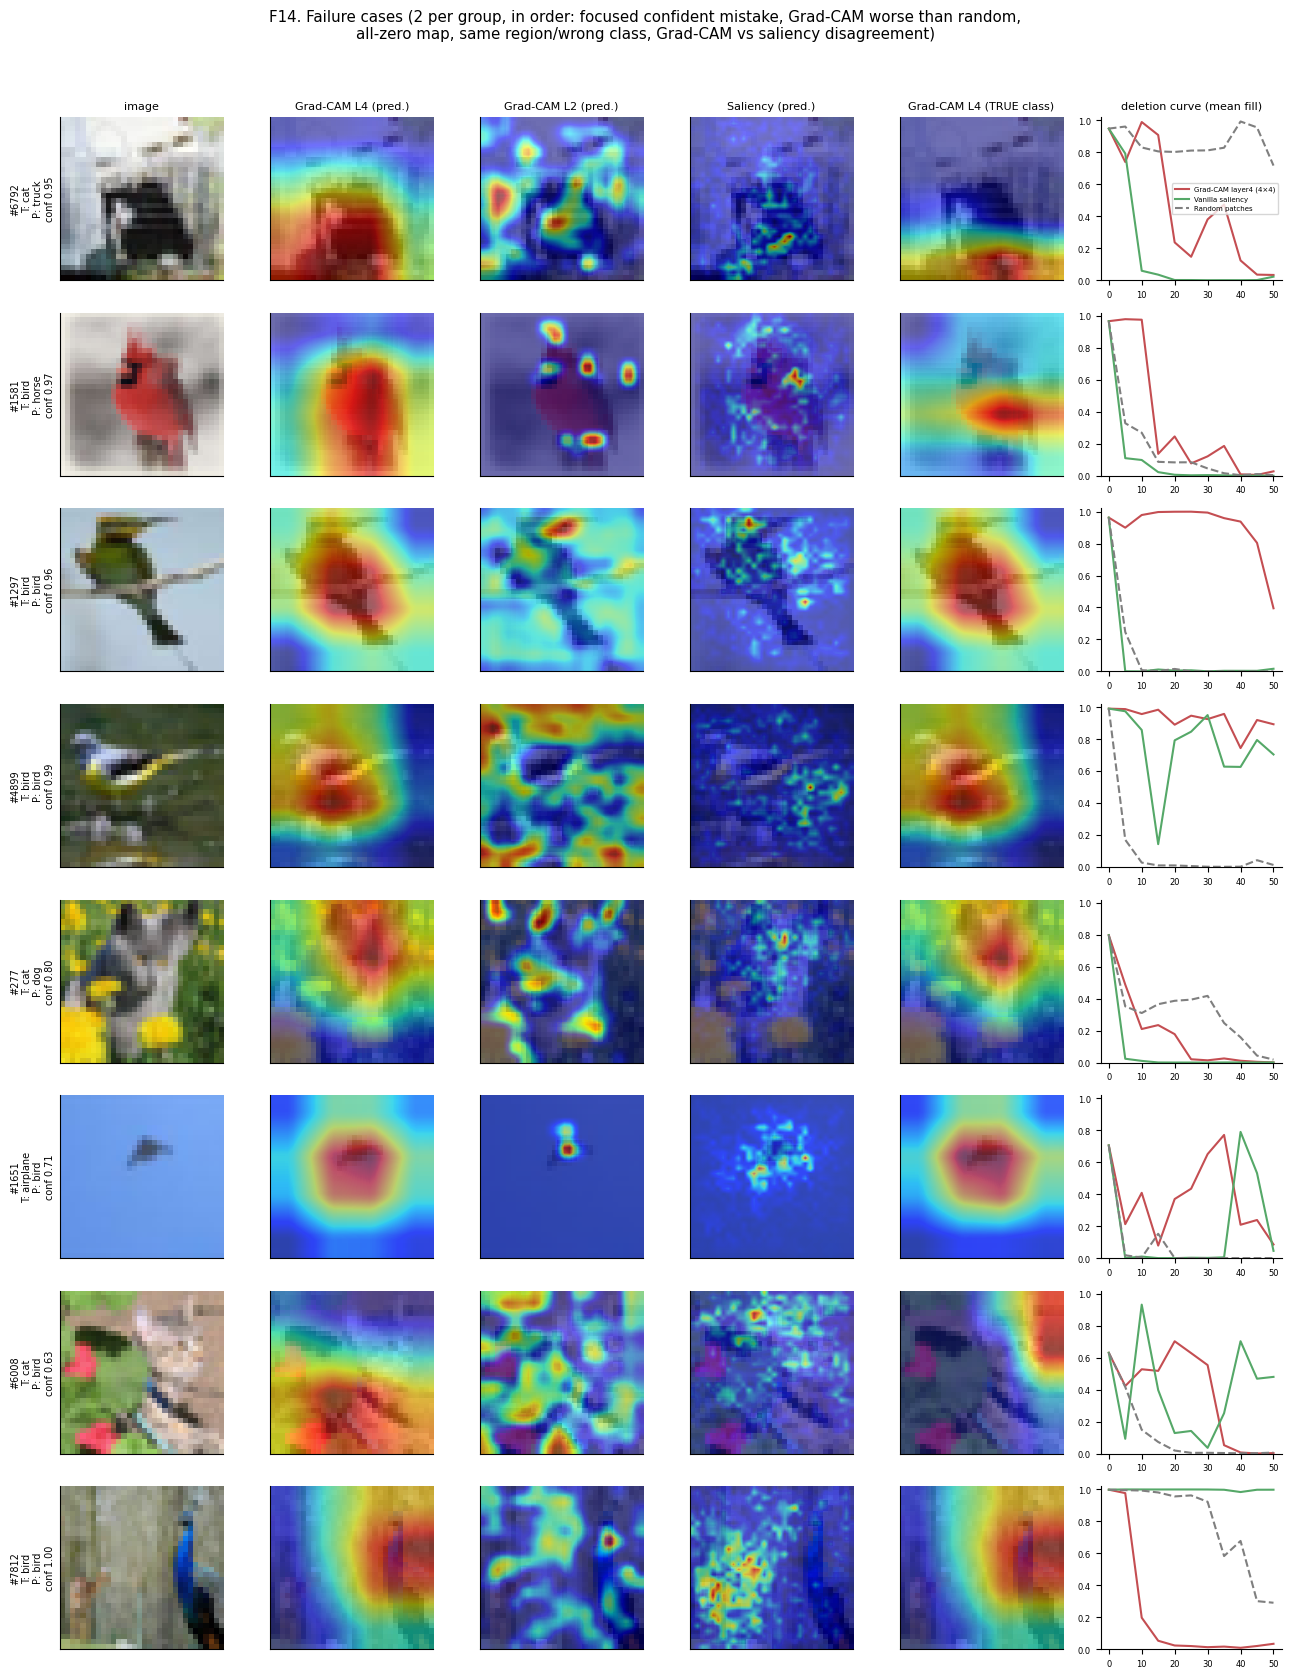

saved figure -> F14_failure_cases_main


In [ ]:
# 10.2  F14 – failure-case panels (one figure per group + a compact main figure)
def plot_cases(rows_idx, title, fname):
    rows_idx = [int(i) for i in rows_idx]
    if not rows_idx: print("no cases for", title); return
    fig, axes = plt.subplots(len(rows_idx), 6, figsize=(13, 2.05 * len(rows_idx)), squeeze=False)
    heads = ["image", "Grad-CAM L4 (pred.)", "Grad-CAM L2 (pred.)", "Saliency (pred.)", "Grad-CAM L4 (TRUE class)", "deletion curve (mean fill)"]
    for r_, i in enumerate(rows_idx):
        row = df.iloc[i]
        show_img(axes[r_, 0], i)
        axes[r_, 0].set_ylabel(f"#{i}\nT: {row.true_name}\nP: {row.pred_name}\nconf {row.conf:.2f}", fontsize=7)
        show_map(axes[r_, 1], i, EXPL["L4"][i]); show_map(axes[r_, 2], i, EXPL["L2"][i])
        show_map(axes[r_, 3], i, EXPL["sal"][i]); show_map(axes[r_, 4], i, EXPL_TRUE["L4"][i])
        ax = axes[r_, 5]
        for k in ["L4", "sal", "rand"]:
            ax.plot(KS * 100, CURVE[k][i, mo_mean], c=COLORS[k], ls="--" if k == "rand" else "-", label=METH_NAME[k])
        ax.set_ylim(0, 1.02); ax.tick_params(labelsize=6)
        if r_ == 0: ax.legend(fontsize=5)
    for c, h in enumerate(heads): axes[0, c].set_title(h, fontsize=8)
    fig.suptitle(title); plt.tight_layout(); savefig(fig, fname)

for g, idx in FAIL.items():
    plot_cases(idx, f"F14 – {g.replace('_', ' ')}", f"F14_{g}")
main_rows = [i for idx in FAIL.values() for i in list(idx)[:2]]
plot_cases(main_rows, "F14. Failure cases (2 per group, in order: focused confident mistake, Grad-CAM worse than random,\n"
           "all-zero map, same region/wrong class, Grad-CAM vs saliency disagreement)", "F14_failure_cases_main")

**Interpretation guide (Step 10):** for each group write the **pattern** you see, and link it to one of Grad-CAM's three assumptions:
* **background reliance** (water → ship, grass → deer) → focused map on the wrong evidence (why H2 can hold)
* **small object lost at 4×4 resolution** → *resolution* assumption
* **look-alike classes** (cat/dog, automobile/truck) → "same region, wrong reading"
* **all-zero maps / evidence removed by ReLU** → *positive-evidence-only* assumption
* **feature interactions** the averaged gradient misses → *linear (first-order) weighting* assumption

---
# STEP 11 — Summary for the report

In [ ]:
# 11.1  Key numbers
save_results()
print("=" * 80)
print(f"Accuracy (analysed set): {RESULTS['test_acc_analysis_set']:.4f} | errors {RESULTS['n_incorrect']} | "
      f"confident mistakes {RESULTS['n_confident_mistakes']} (conf ≥ {RESULTS['cm_conf_threshold']:.3f})")
print("\n--- RQ1/RQ2 (area-50) ---")
for r in T2_raw[T2_raw.metric == "area50"].itertuples():
    print(f"{METH_NAME[r.method]:<26} r = {r.r:+.3f} (p_holm {r.p_holm:.1e}) {r.H1:<22} AUROC(CM) = {fmt_ci(r.auroc_cm, r.auroc_cm_lo, r.auroc_cm_hi)}")
print(f"{'Confidence (reference)':<26} AUROC(CM) = {fmt_ci(*CONF_AU_CM)}")
print("\n--- Sanity check: median Spearman after full randomisation ---")
for k, v in RESULTS["sanity_full_randomisation_median_spearman"].items(): print(f"{k:<26} {v:+.3f}")
print("\n--- RQ3: Grad-CAM / saliency vs random (r > 0 = better than random) ---")
for r in T4_raw[T4_raw.other == "rand"].itertuples():
    print(f"{METH_NAME[r.method]:<26} fill={r.mode:<6} r = {r.r:+.3f}  win {100*r.win_rate:5.1f}%  {r.verdict}")
print("\n--- RQ4: advantage on mistakes (r < 0 = less faithful on mistakes) ---")
for r in T5_raw.itertuples():
    print(f"{METH_NAME[r.method]:<26} fill={r.mode:<6} raw r = {r.r_raw:+.3f} {stars(r.p_raw_holm):<3} | matched r = {r.r_match:+.3f} {stars(r.p_match_holm):<3} | {r.H4_matched}")
print("=" * 80)
print("Figures:", sorted(p.name for p in FIG.glob("*.png")))
print("Tables :", sorted(p.name for p in TAB.glob("*.csv")))

Accuracy (analysed set): 0.9314 | errors 686 | confident mistakes 172 (conf ≥ 0.944)

--- RQ1/RQ2 (area-50) ---
Grad-CAM layer2 (16×16)    r = -0.292 (p_holm 6.9e-37) ✗ opposite direction   AUROC(CM) = 0.428 [0.386, 0.467]
Grad-CAM layer3 (8×8)      r = +0.405 (p_holm 1.3e-68) ✓ supported            AUROC(CM) = 0.671 [0.628, 0.706]
Grad-CAM layer4 (4×4)      r = -0.393 (p_holm 9.1e-66) ✗ opposite direction   AUROC(CM) = 0.390 [0.348, 0.430]
Vanilla saliency           r = -0.189 (p_holm 1.2e-16) ✗ opposite direction   AUROC(CM) = 0.401 [0.358, 0.441]
Confidence (reference)     AUROC(CM) = 0.799 [0.780, 0.817]

--- Sanity check: median Spearman after full randomisation ---
Grad-CAM layer2 (16×16)    -0.007
Grad-CAM layer3 (8×8)      +0.005
Grad-CAM layer4 (4×4)      +0.098
Vanilla saliency           +0.197

--- RQ3: Grad-CAM / saliency vs random (r > 0 = better than random) ---
Grad-CAM layer2 (16×16)    fill=black  r = -0.038  win  51.1%  ✗ opposite direction
Grad-CAM layer3 (8×8)      

In [ ]:
# 11.2  Zip everything (except large arrays) for download / GitHub
zip_dir = Path("/content/xai_results_export"); shutil.rmtree(zip_dir, ignore_errors=True)
shutil.copytree(RES, zip_dir, ignore=shutil.ignore_patterns("*.npy", "*.npz", "checkpoint.pt"))
archive = shutil.make_archive("/content/xai_results", "zip", zip_dir)
print("archive:", archive)
try:
    from google.colab import files; files.download(archive)
except Exception:
    pass

archive: /content/xai_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Where each output goes in the report

| Report section | Main text | Appendix |
|---|---|---|
| 3. Setup | T1, (F3) | F1, F2, T1c |
| 4.1 RQ1/RQ2 | **F5, T2**, F6 | F4b, F7, F8, F9, T2b–T2e |
| 4.2 Sanity check | **F10a** | F10b, T3 |
| 4.3 RQ3 Deletion | **F11, T4b** | F11b, F11c, T4a |
| 4.4 RQ4 | **F12, T5** | – |
| 5. Sensitivity | **T6 / F13** | – |
| 6. Failure cases | **F14 (main)** | F14 per group, T7 |
| Qualitative intro | **F4** | – |

**Threats to validity to discuss:** out-of-distribution masking (3 fills + random control, ROAR out of scope) · one dataset and one architecture · low-resolution maps (4×4 at layer4) · bilinear upsampling affects area-50 · random patches cover image borders less often than the centre · number of confident mistakes · multiple comparisons (Holm) · RQ1/RQ2 are correlational, only RQ3/RQ4 intervene on the input.

**LLM-use disclosure (fill in):** state which parts were written with an AI assistant and how you verified them (debug run, library cross-checks in 3.3, sanity checks, manual inspection of figures, re-deriving the statistics).

In [ ]:
# Extra check: what does the model predict after deletion? (bird / mask-shape artefact)
mo = MODES.index("mean")
worst = np.argsort(-(AUC["L4"][:, mo] - AUC["rand"][:, mo]))[:50]
x = X_TEST[worst].to(DEVICE); B = len(worst)
gen = torch.Generator(device=DEVICE).manual_seed(0)
kk = int(np.argmin(np.abs(KS[1:] - 0.2)))            # 20% of pixels deleted
m_gc = masks_from_scores(heatmap_scores(torch.from_numpy(EXPL["L4"][worst].reshape(B, -1)).to(DEVICE), gen))[:, kk]
m_rd = masks_from_scores(random_patch_scores(B, gen))[:, kk]
print("true classes:", df.iloc[worst].true_name.value_counts().head(3).to_dict())
for name, m in [("Grad-CAM L4", m_gc), ("random", m_rd)]:
    for mode in MODES:
        fill = fill_for(x, mode); mm = m.view(B, 1, 32, 32).float()
        with torch.no_grad():
            p = F.softmax(model(x * (1 - mm) + fill * mm), 1).cpu()
        print(f"{name:12s} fill={mode:5s} -> predicted:", pd.Series([CLASSES[i] for i in p.argmax(1)]).value_counts().head(3).to_dict())

true classes: {'bird': 44, 'ship': 4, 'cat': 2}
Grad-CAM L4  fill=black -> predicted: {'bird': 39, 'airplane': 7, 'ship': 3}
Grad-CAM L4  fill=mean  -> predicted: {'bird': 45, 'ship': 4, 'cat': 1}
Grad-CAM L4  fill=blur  -> predicted: {'bird': 40, 'ship': 4, 'deer': 2}
random       fill=black -> predicted: {'airplane': 26, 'truck': 10, 'cat': 8}
random       fill=mean  -> predicted: {'airplane': 24, 'truck': 11, 'cat': 3}
random       fill=blur  -> predicted: {'bird': 39, 'airplane': 4, 'ship': 4}


In [ ]:
# How often does deleting 20% of pixels change the prediction, and to which class? (all images)
kk = int(np.argmin(np.abs(KS[1:] - 0.2)))
rows = []
for name in ["L4", "rand"]:
    for mode in MODES:
        new_pred = []
        for b0 in range(0, N, 500):
            b1 = min(N, b0 + 500); B = b1 - b0
            x = X_TEST[b0:b1].to(DEVICE)
            gen = torch.Generator(device=DEVICE).manual_seed(b0)
            if name == "L4":
                m = masks_from_scores(heatmap_scores(torch.from_numpy(EXPL["L4"][b0:b1].reshape(B, -1)).to(DEVICE), gen))[:, kk]
            else:
                m = masks_from_scores(random_patch_scores(B, gen))[:, kk]
            mm = m.view(B, 1, 32, 32).float()
            with torch.no_grad():
                new_pred.append(model(x * (1 - mm) + fill_for(x, mode) * mm).argmax(1).cpu())
        new_pred = torch.cat(new_pred).numpy()
        changed = new_pred != df.pred.values
        top = pd.Series([CLASSES[i] for i in new_pred[changed]]).value_counts(normalize=True).head(3).round(2).to_dict()
        rows.append({"Deletion": METH_NAME[name], "Fill": mode,
                     "% predictions changed": round(100 * changed.mean(), 1),
                     "Most common new class (share of changes)": top})
T8 = save_table(pd.DataFrame(rows), "T8_prediction_shift_after_deletion")

,Deletion,Fill,% predictions changed,Most common new class (share of changes)
0,Grad-CAM layer4 (4×4),black,49.2,"{'bird': 0.43, 'airplane': 0.19, 'cat': 0.18}"
1,Grad-CAM layer4 (4×4),mean,50.1,"{'bird': 0.36, 'airplane': 0.18, 'cat': 0.16}"
2,Grad-CAM layer4 (4×4),blur,33.3,"{'cat': 0.24, 'bird': 0.23, 'airplane': 0.2}"
3,Random patches,black,50.2,"{'truck': 0.49, 'airplane': 0.27, 'cat': 0.13}"
4,Random patches,mean,37.0,"{'truck': 0.46, 'airplane': 0.18, 'cat': 0.09}"
5,Random patches,blur,10.0,"{'cat': 0.27, 'airplane': 0.13, 'truck': 0.11}"


saved table -> T8_prediction_shift_after_deletion
